# 信用の世界経済は一つか
## ―― 国のモデルを連結し、縮約し、射影する

文責: JRF ( http://jrf.cocolog-nifty.com/statuses/ )<br>
モデル化・執筆・証明の補助: Claude Opus 5.5 (Anthropic)<br>
2026年10月

---

### この文書について

この文書は、前のノート「[信用創造はどこで止まるのか](https://github.com/JRF-2018/credit_simulation_v6/blob/master/notebooks/credit_creation_v6.ipynb)」の続編である。前のノートでは、「信用創造ダイナミクス v5」を読み解いた。そのうえで、利子が誰かの所得として経済に戻る、二階級の信用循環モデルに組み直した。

v5 は国家の出てこない、いわば「信用の世界経済」のモデルだった。そこから、次のような直感が出てくる。

> 国家も、企業に類するプレイヤーにすぎないのではないか。企業が何社も経済に埋め込まれているように、国家も複数「埋め込める」のではないか。国家の違いは、埋め込んだ所のパラメータの違いとして表せるのではないか。

この直感を逆から言うと、こうなる。

> 大きさの違う二つの国のモデル $M_B$, $M_C$ をつないだ経済を、一つの国のモデル $M_A$ として描けるのではないか。$M_B$, $M_C$ のパラメータの変化に対応する $M_A$ のパラメータの変化を決められるのではないか。逆に、$M_A$ の変化を $M_B$, $M_C$ に「射影」できるのではないか。この「連結」は、半群のような代数になるのではないか。

この文書は、この問いに答える。国と国をつなぐのだから、扱うのは**開放経済**(国の外との取引がある経済)である。結論を先に書いておく。

1. **会計(貸借と取引の流れ)の連結は、厳密に**できる。段階的に連結しても、一度に連結しても同じになる(結合性)。これは Lean で証明する。
2. **線形の行動式(消費性向など)は、その時点については厳密に**集計できる。集計したパラメータは、流れの大きさで重み付けた平均になり、この平均も結合的である。
3. **時間の中での動き(動学)は、一般には厳密に縮約できない。** ただし、国々が貿易と金融でしっかりつながっていれば、成長率がそろい、構成比が落ち着く。そのため、平時には一国のモデルでほぼ厳密に描ける。
4. **折れ線の閾値などの非線形や、国ごとに違うショック、為替の動きがあると、縮約はずれる。** ただし、定性的な動きは多くの場合一致する。
5. **射影は一つに決まらない。** 配分の規則を選ぶと決まり、世界全体の結果はほとんど規則によらない。しかし、国ごとの結果と貸し借りは、規則しだいで大きく変わる。
6. **縮約した一国モデルからは、内側の格差(中核と周辺)が見えなくなる。**

### 読み方

- コードセルは上から順に実行すれば全部動く。使うのは numpy, scipy, matplotlib のみで、Google Colab でもそのまま動く。
- Lean の証明は、`%%writefile` で `credit_linkage.lean` に書き出し、最後(第 15 節)にまとめてチェックする。
- 図の軸ラベルは英語にしてある。

### 目次

0. 準備
1. 前のノートのおさらい
2. 開放経済の会計: 部門収支と連結
3. 多地域の信用循環モデル
4. つながりの基本: ショックはどう伝わるか
5. パラメータの集計: 加重平均と線形の縮約
6. 動学の縮約: つながりが構成比を落ち着かせる
7. 非線形の縮約: 折れ目と分布
8. 射影
9. 結合性と、国家の統合・分裂
10. 中核と周辺
11. 通貨が別々のとき
12. v5 をもう一度読む
13. まとめ: 問いへの答え
14. モデル全体についての定理: 定理 A・B・C
15. Lean の一括チェック
16. 参考文献と過去の議論

## 0. 準備

In [1]:
import numpy as np
import matplotlib.pyplot as plt

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.dpi': 100,
})

## 1. 前のノートのおさらい

前のノートの改良モデル(「信用循環モデル」)の要点だけを書いておく。式の詳しい読み方は、前のノートの第 7 節にある。

- **部門**は五つある。
  - 企業: 借りて資本(在庫・設備・知識)を積む。
  - 労働者: 賃金のほとんどを使う。
  - 金利生活者: 利子と配当を受け取り、あまり使わない。
  - 政府: 支出 $G$・税・国債 $B$。
  - 銀行: 貸出が預金を作る。
- **利子は経済に戻る。** 利払いは金利生活者の所得になる。v5 では利子が経済から消えていたことが、必ず起きる崩壊の原因だった。
- **所得は需要で決まる**(労働者の消費 + 金利生活者の消費 + 投資 + 政府支出)。生産能力 $K/v$ を超えた需要は実現しない。
- **投資の希望**は、前の期の利潤率(とトービンの $q$)で決まる。足りない資金は借りる。ただし、借入の残高は担保(株式的富 $E$ と資本 $K$)で頭打ちになる。
- **株式的富** $E$ は、期待利潤を「貸出金利 + リスクプレミアム」で割り引いた価値である。$E$ が急に縮むと、資本の損耗が増える(在庫維持能力の喪失)。

利払い負担率 $\Phi=r_LL/Y$ や、利払い前の純利潤分配率 $\theta^*$ は、このモデルでは仮定ではなく、結果として観測する量だった。

この文書では、このモデルを **N 個の地域に広げ、地域どうしを貿易と金融でつなぐ。**

## 2. 開放経済の会計: 部門収支と連結

### 2.1 部門収支の恒等式

一つの国の中では、ある部門の黒字(使わずに残したお金)は、必ず別の部門の赤字(借りて使ったお金)になる。国の外との取引があると、その差は外国に向かう。これが**部門収支の恒等式**である。

$$
\underbrace{(\text{家計の貯蓄})}_{\text{家計の黒字}} + \underbrace{(\text{企業の内部資金} - \text{投資})}_{\text{企業の黒字}} + \underbrace{(\text{税} - G - \text{国債の利払い})}_{\text{政府の黒字}} = \underbrace{\text{経常収支}}_{\text{外国に対する黒字}}
$$

経常収支は、「輸出 − 輸入 + 外国から受け取る利子・配当 − 外国に払う利子・配当」である。ある国の経常収支の黒字は、どこか別の国の赤字なので、**世界全体の経常収支の和は 0** になる。

### 2.2 連結とは

単位(国・地域・企業)を有限集合 $\iota$ とし、単位 $i$ から単位 $j$ への支払いを $f(i,j)$ と書く。単位 $i$ の**純受取**(受け取り − 支払い)は

$$
\mathrm{NR}_f(i) = \sum_j f(j,i) - \sum_j f(i,j)
$$

である。経常収支や純貸出は、これに当たる。

単位をまとまり(国をまとめた地域など)に分ける写像を $\pi:\iota\to\kappa$ とする。まとまり $J$ から $K$ への支払いは、

$$
(\pi_* f)(J,K) = \sum_{i:\,\pi(i)=J}\ \sum_{j:\,\pi(j)=K} f(i,j)
$$

と定める。これが**連結**である。$J=K$ の項(まとまりの中の取引)は、まとまりの純受取からは消える(相殺される)。

これについて、次の三つが言える。Lean で証明する。

- **(T2a)** 世界全体の純受取の和は 0。
- **(T2b)** まとまりの純受取は、構成する単位の純受取の和に等しい。
- **(T1)** 段階的に連結しても、一度に連結しても同じ:$\sigma_*(\pi_* f) = (\sigma\circ\pi)_* f$。さらに、何もまとめない連結は元のまま:$\mathrm{id}_* f = f$。

T1 が「連結の結合性」の正確な形である。二国の連結 $B\oplus C$ を繰り返して $(B\oplus C)\oplus D$ と $B\oplus(C\oplus D)$ を作ると、どちらも三国を一度に連結したもの($\{B,C,D\}$ を一つにまとめる写像による連結)に等しい。

なお、連結は単純な「二項演算の半群」にはならない。$(B\oplus C)$ と $D$ をつなぐには、$D$ と $B$、$D$ と $C$ の取引を別々に知っている必要がある。ところが、まとめた $B\oplus C$ はその区別を失っているからである。正しい構造は、**単位の分け方(分割)と、それを粗くしていく写像の合成**であり、T1 はその合成が整合することを言っている。

In [2]:
%%writefile credit_linkage.lean
import Mathlib

/-!
# 信用循環モデルの連結と縮約: 言える部分の証明

単位(地域・国・企業)の集合を有限型 `ι` とし、単位 `i` から単位 `j` への支払いを `f i j` で表す。
連結(縮約)は、単位を「どのまとまりに入れるか」を表す写像 `π : ι → κ` で与える。
-/

open Finset BigOperators

namespace CreditLinkage

Overwriting credit_linkage.lean


In [3]:
%%writefile -a credit_linkage.lean
/-- 支払いの行列 `f` を、写像 `π` でまとめた支払いの行列(まとまりどうしの支払いの合計)。 -/
noncomputable def consolidate {ι κ : Type*} [Fintype ι] [DecidableEq κ]
    (π : ι → κ) (f : ι → ι → ℝ) : κ → κ → ℝ :=
  fun J K => ∑ i ∈ univ.filter (fun i => π i = J), ∑ j ∈ univ.filter (fun j => π j = K), f i j

/-- 単位 `i` の純受取(受け取り − 支払い)。経常収支や純貸出に当たる。 -/
def netReceipt {ι : Type*} [Fintype ι] (f : ι → ι → ℝ) (i : ι) : ℝ :=
  ∑ j, f j i - ∑ j, f i j

/-- T2a: 世界全体の純受取の和は 0(全地域の経常収支の和は 0)。 -/
theorem sum_netReceipt_eq_zero {ι : Type*} [Fintype ι] (f : ι → ι → ℝ) :
    ∑ i, netReceipt f i = 0 := by
  unfold netReceipt
  rw [Finset.sum_sub_distrib, Finset.sum_comm]
  ring

/-- まとまりごとに和を取ってから足すと、全体の和になる。 -/
lemma sum_fibers {ι κ : Type*} [Fintype ι] [Fintype κ] [DecidableEq κ]
    (π : ι → κ) (g : ι → ℝ) :
    ∑ J, ∑ i ∈ univ.filter (fun i => π i = J), g i = ∑ i, g i :=
  Finset.sum_fiberwise univ π g

/-- T2b: まとまりの純受取は、構成する単位の純受取の和に等しい(まとまりの中の取引は相殺される)。 -/
theorem netReceipt_consolidate {ι κ : Type*} [Fintype ι] [Fintype κ] [DecidableEq κ]
    (π : ι → κ) (f : ι → ι → ℝ) (J : κ) :
    netReceipt (consolidate π f) J = ∑ i ∈ univ.filter (fun i => π i = J), netReceipt f i := by
  unfold netReceipt consolidate
  rw [Finset.sum_sub_distrib]
  congr 1
  · rw [sum_fibers π (fun i => ∑ j ∈ univ.filter (fun j => π j = J), f i j), Finset.sum_comm]
  · rw [Finset.sum_comm]
    apply Finset.sum_congr rfl
    intro i _
    exact sum_fibers π (fun j => f i j)

Appending to credit_linkage.lean


In [4]:
%%writefile -a credit_linkage.lean
/-- 二段の和: まとまり J(σ J = M となるもの)ごとに、J に入る単位の和を取って足すと、
σ ∘ π で M に入る単位の和になる。 -/
lemma fiber_comp {ι κ μ : Type*} [Fintype ι] [Fintype κ] [DecidableEq κ] [DecidableEq μ]
    (π : ι → κ) (σ : κ → μ) (M : μ) (g : ι → ℝ) :
    ∑ J ∈ univ.filter (fun J => σ J = M), ∑ i ∈ univ.filter (fun i => π i = J), g i
      = ∑ i ∈ univ.filter (fun i => σ (π i) = M), g i := by
  rw [← Finset.sum_fiberwise_of_maps_to (s := univ.filter (fun i => σ (π i) = M))
        (t := univ.filter (fun J => σ J = M)) (g := π) (by intro i hi; simpa using hi)]
  apply Finset.sum_congr rfl
  intro J hJ
  simp only [mem_filter, mem_univ, true_and] at hJ
  apply Finset.sum_congr _ (fun _ _ => rfl)
  ext i; simp only [mem_filter, mem_univ, true_and]
  constructor
  · intro h; exact ⟨by rw [h, hJ], h⟩
  · intro h; exact h.2

/-- T1: 段階的に連結しても、一度に連結しても同じ(連結は写像の合成と整合する)。
二地域の連結 B ⊕ C を繰り返して (B ⊕ C) ⊕ D と B ⊕ (C ⊕ D) を作っても、どちらも
三地域を一度に連結したものに等しい。これが「連結の結合性」の正確な形である。 -/
theorem consolidate_comp {ι κ μ : Type*} [Fintype ι] [Fintype κ] [DecidableEq κ] [DecidableEq μ]
    (π : ι → κ) (σ : κ → μ) (f : ι → ι → ℝ) :
    consolidate σ (consolidate π f) = consolidate (σ ∘ π) f := by
  funext M N
  unfold consolidate
  simp only [Function.comp]
  rw [← fiber_comp π σ M]
  apply Finset.sum_congr rfl
  intro J _
  rw [Finset.sum_comm]
  apply Finset.sum_congr rfl
  intro i _
  exact fiber_comp π σ N (fun j => f i j)

/-- 何もまとめない連結(恒等写像)は、元のままである(単位元)。 -/
theorem consolidate_id {ι : Type*} [Fintype ι] [DecidableEq ι] (f : ι → ι → ℝ) :
    consolidate id f = f := by
  funext J K
  unfold consolidate
  simp [Finset.filter_eq']

Appending to credit_linkage.lean


## 3. 多地域の信用循環モデル

前のノートのモデルを、N 個の地域に広げる。この節と第 4〜10 節では、**通貨は共通で、中央銀行も一つ**とする。米国の州や、ユーロ圏の国のような関係である。通貨が別々の場合は、第 11 節で扱う。

### 3.1 地域をつなぐもの

**貿易**
- 地域 $j$ は、支出 $D_j$(消費 + 投資 + 政府支出)のうち $m_j$ を輸入する。
- 輸入の相手は、貿易の行列 $T$ で配る。$T[j,i]$ は、地域 $j$ の輸入のうち地域 $i$ から買う割合である。
- 地域 $j$ の支出のうち地域 $i$ の生産になる割合を $Z[i,j]$ とすると、$Z=\mathrm{diag}(1-m)+T^\top\mathrm{diag}(m)$ になる。所得は $Y=Z\,D$ である。
- 支出 $D$ は、所得 $Y$ の一次式 $D=C\,Y+a$ なので、所得は連立一次方程式 $Y=Z(CY+a)$ を解いて決まる。生産能力を超えた分は実現しない。

**金融**
- 地域 $j$ の企業の借入と政府の国債への請求権のうち、割合 $F[j,i]$ を地域 $i$ の金利生活者が持つ(保有の行列)。
- 地域 $i$ の金利生活者が受け取る利子・配当は、$\sum_j F[j,i]\cdot(\text{地域 } j \text{ が払う利子・配当})$ になる。
- 税は、住んでいる地域で払う。

**決済残高**
- 経常収支と、外国の資産を新たに買う額は、一致するとは限らない。その差は、共通の中央銀行への請求権(ユーロ圏の TARGET2 残高のようなもの)$S_i$ の増減として残る。$\sum_i S_i=0$ である。
- これで会計が閉じる。

**生産能力に届いたとき**
- ある地域の財への需要が、その地域の生産能力を超えたとする。そのときは、その地域の財を、すべての買い手に同じ割合で行き渡らせる。
- 買えなかった分は、買い手の消費から差し引く(強制貯蓄)。
- こうしておくと、部門収支の恒等式が、生産能力に届いたときも厳密に成り立つ。

一つの地域だけで動かすと、前のノートのモデルと(生産能力に届く場面も含めて)一致する。

### 3.2 コード

`WORLD_DEFAULT` は地域ごとに持てるパラメータである。スカラーで与えれば全地域共通、長さ N の配列で与えれば地域別になる。`WORLD_STRUCT` は、地域の間の構造と初期値である。`WORLD_KEYS` は記録する量で、各行のコメントに意味を書いた。

In [5]:
import numpy as np

# 地域ごとに持てるパラメータ(スカラーなら全地域共通、長さ N の配列なら地域別)
WORLD_DEFAULT = dict(
    T=150.0, dt=0.1,
    v=2.5,          # 資本係数: 生産能力 Y_p = K/v
    u_max=1.1,      # 資本稼働率の上限
    omega=0.65,     # 賃金分配率
    d0=0.05,        # 平時の損耗率 δ0
    kappa=3.0,      # 株式的富が縮むときの損耗増幅
    c_w=0.95,       # 労働者の消費性向
    c_r=0.35,       # 金利生活者の所得からの消費性向
    c_v=0.02,       # 金利生活者の金融資産からの消費性向
    payout=0.6,     # 配当性向
    tau=0.25,       # 税率(居住地ベース)
    gG=0.20,        # 政府支出 G = gG·Y_p/u_max
    fiscal=0.0,     # 財政ルール: 税率を (国債/所得 − b_target) に比例して上げる強さ(財政統合中は統合全体の比率を見る)
    b_target=0.6,
    r_cb=0.03,      # 共通の政策金利(= 国債金利 = 決済残高の金利)
    spread=0.01,    # 貸出スプレッド
    spread_loss=2.0,# 貸倒れ率に応じたスプレッドの上乗せ
    rho=0.05,       # 法定準備率
    g0=-0.02, g1=0.75, g2=0.0,  # 純投資率 = g0 + g1·Π/K + g2·(u − 0.85) + g_q·(q − q_ref)
    g_q=0.0, q_ref=0.9,
    prem=0.02,      # 株式のリスクプレミアム
    lam=0.6,        # 担保制約 L ≤ lam·(E + K)
    T_adj=2.0,      # 担保制約を超えたときの返済の速さ(年)
    default_share=0.5,
    tau_e=2.0,      # 期待利潤の適応の時定数(年)
    m=0.0,          # 輸入性向(支出のうち他地域から買う割合)
    a_growth=0.015, pop_growth=0.005,
    labor_cap=False, phillips=0.0, e_star=0.90,
    theta_c=5.0,    # 貿易の取り分の競争力への感応度(phi_trade を与えたときだけ使う)
    verdoorn=0.0,   # 競争力の伸び = verdoorn ×(成長率 − 世界平均)− price_adj ×(稼働率 − 世界平均)− diffuse × ln A
    price_adj=0.0,  # 売れずに設備が遊ぶ地域は、賃金・価格が下がって競争力を取り戻す(安定化の力)
    diffuse=0.05,   # 技術の拡散(競争力の差は平均へ引き戻される)
)
# 地域の間の構造(N×N 行列)と初期値
WORLD_STRUCT = dict(
    trade=None,     # trade[j, i]: 地域 j の輸入のうち地域 i から買う割合(行の和 1、対角 0)。None なら均等
    hold=None,      # hold[j, i]: 地域 j の企業の借入・国債への請求権のうち、地域 i の金利生活者が持つ割合(行の和 1)。None なら単位行列
    K0=None,        # 地域ごとの初期の資本(None なら 250 を N 等分)
    init='steady',  # 'steady': 予備走行(κ=0, ショックなし)で釣り合った比率を求めて初期値にする
    state=None,     # 初期状態を直接与える辞書(K, L, B, S, Pi_e)。与えたときは init を無視する
    phi_trade=None, # 貿易の自由度 φ(0〜1)。与えると、支出の地域への配分を競争力 A から
                    # S_ij = K_i A_i^θ φ^{[i≠j]} / Σ_k K_k A_k^θ φ^{[k≠j]} で決め、m と trade はそれで上書きする
    A0=None,        # 競争力の初期値(None なら全地域 1)
    fx=None,        # 通貨が別々のとき: dict(currency=[地域ごとの通貨 0/1], regime='float' か 'fixed',
                    #   eta=輸入の価格弾力性, k_ca=経常収支への為替の反応, k_r=金利差への反応,
                    #   k_q=株式の収益見通し(トービンの q)の差への反応(資本の流れ),
                    #   k_u=稼働率の差への反応(不況の国の通貨が下がる), e0=為替の初期値,
                    #   shifts=[(時刻, 新しい平価, 期間)]: 固定相場での平価の変更)
                    # e は通貨 1 の価値を通貨 0 で測ったもの。各地域の量は自国通貨建て
    fiscal_union=None,  # (開始時刻, 終了時刻): その間、全地域の赤字を合算し、新しい国債を所得の比率で割り振る
                        # (過去の国債は各地域に残る)。差額は地域間の財政移転として経常収支に入る
    shocks=(),      # [(t, {param: 値 または 配列}, 期間)]
)

WORLD_KEYS = [
    't',          # 時刻(年)
    'Y',          # 実現した所得(= 生産)
    'Yd',         # 需要で決まる所得(生産能力の上限をかける前)
    'D',          # 地域の支出(消費 + 投資 + 政府支出)
    'K',          # 資本
    'L',          # 企業の借入残高
    'B',          # 国債残高
    'S',          # 決済残高(共通の中央銀行への請求権)
    'E',          # 株式的富
    'Pi',         # 企業の純利潤
    'X',          # 輸出
    'M',          # 輸入
    'CA',         # 経常収支 = 輸出 − 輸入 + 純第一次所得(利子・配当の受け払い)
    'NFA',        # 対外純資産(ポートフォリオ + 決済残高)
    'rent_in',    # 金利生活者が受け取る利子・配当(居住地ベース)
    'r_L',        # 貸出金利
    'u',          # 資本稼働率
    'g',          # 資本の純成長率
    'Phi',        # 利払い負担率 r_L L / Y
    'theta_star', # 利払い前の純利潤分配率
    'q',          # トービンの q
    'delta',      # 実際の損耗率
    'emp',        # 雇用率
    'omega',      # 賃金分配率
    'tax',        # 税収
    'G',          # 政府支出
    'sb_err',     # 部門収支の恒等式の誤差(0 になるはず)
    'pay',        # 企業の借入・国債に対して地域が払う利子・配当
    'I',          # 投資
    'Pi_e',       # 期待利潤
    'A',          # 競争力
    'm',          # 輸入性向
    'tr',         # 地域間の財政移転(受け取り)
    'tau',        # 税率(財政ルールで動く)
    'e',          # 為替レート(通貨 1 の価値を通貨 0 で測ったもの)
    'cv',         # 自国通貨 1 単位の、通貨 0 での価値
]


def softmin(a, b, w):
    """min(a, b) の滑らか版(幅 w)。"""
    return -w * np.logaddexp(-a / w, -b / w)


def _vec(x, N):
    return np.full(N, float(x)) if np.isscalar(x) else np.asarray(x, float).copy()


def simulate_world(N=2, **kw):
    struct = {k: kw.pop(k) if k in kw else v for k, v in WORLD_STRUCT.items()}
    p = {k: (kw[k] if k in kw else v) for k, v in WORLD_DEFAULT.items()}
    flags = {k: p[k] for k in ('labor_cap',)}
    P = {k: _vec(v, N) for k, v in p.items() if k not in ('T', 'dt', 'labor_cap')}
    dt = p['dt']
    n = int(round(p['T'] / dt))
    Tm = (np.ones((N, N)) - np.eye(N)) / max(N - 1, 1) if struct['trade'] is None else np.asarray(struct['trade'], float)
    F = np.eye(N) if struct['hold'] is None else np.asarray(struct['hold'], float)
    K = _vec(250.0 / N, N) if struct['K0'] is None else _vec(struct['K0'], N)
    L, B, S = 60.0 / 250.0 * K, 60.0 / 250.0 * K, np.zeros(N)
    omega = P['omega'].copy()
    r_L0 = (P['r_cb'] + P['spread']) / (1 - P['rho'])
    Pi_e = (1 - omega) * K / P['v'] * 0.9 - P['d0'] * K - r_L0 * L
    if struct['state'] is not None:
        st = struct['state']
        K, L, B, S, Pi_e = (_vec(st[k], N) for k in ('K', 'L', 'B', 'S', 'Pi_e'))
        Pi_prev0 = _vec(st.get('Pi_prev', st['Pi_e']), N)
    elif struct['init'] == 'steady':
        pre = simulate_world(N=N, **{**kw, 'kappa': 0.0, 'T': 300.0, 'phillips': 0.0},
                             trade=struct['trade'], hold=struct['hold'], K0=K, init=None, state=None, shocks=(),
                             phi_trade=struct['phi_trade'], A0=struct['A0'], fiscal_union=None,
                             fx=None if struct['fx'] is None else {k: v for k, v in struct['fx'].items() if k != 'shifts'})
        f = K.sum() / pre['K'][-1].sum()
        K, L, B, S, Pi_e = (pre[k][-1] * f for k in ('K', 'L', 'B', 'S', 'Pi'))
    Pi_prev, loss_rate, delta, E_prev = Pi_e.copy(), np.zeros(N), P['d0'].copy(), None
    if struct['state'] is not None:
        Pi_prev = Pi_prev0
    a = np.ones(N)
    Pop = (0.9 * K / P['v']) / 0.92
    A = np.ones(N) if struct['A0'] is None else _vec(struct['A0'], N)
    fx = struct['fx']
    cur = np.zeros(N, dtype=int) if fx is None else np.asarray(fx['currency'], int)
    e = 1.0 if fx is None else fx.get('e0', 1.0)
    m_base = P['m'].copy()
    shift_base = {}                                   # 平価変更の起点の為替
    out = {k: np.empty((n, N)) for k in WORLD_KEYS}
    out['t'] = np.empty(n)
    shocks = [(sh[0], sh[1], sh[2] if len(sh) > 2 else 0.0, {}) for sh in struct['shocks']]
    for i in range(n):
        t = i * dt
        for ts, ch, dur, base in shocks:
            if ts - dt / 2 <= t <= ts + dur + dt / 2:
                if not base:
                    base.update({k: P[k].copy() for k in ch})
                w = 1.0 if dur <= 0 else min(1.0, (t - ts + dt / 2) / dur)
                for k, v in ch.items():
                    P[k] = base[k] + w * (_vec(v, N) - base[k])
                if 'omega' in ch:
                    omega = P['omega'].copy()
        if struct['phi_trade'] is not None:
            # 重力型: 支出は、売り手の生産能力 K_i と競争力 A_i^θ に比例して配られる
            Wt = (K * A ** P['theta_c'])[:, None] * np.where(np.eye(N, dtype=bool), 1.0, struct['phi_trade'])
            Sh = Wt / Wt.sum(axis=0, keepdims=True)          # Sh[i, j]: 地域 j の支出のうち i から買う割合
            P['m'] = 1 - np.diag(Sh)
            Tm = (Sh / np.maximum(P['m'], 1e-12)[None, :]).T
            np.fill_diagonal(Tm, 0.0)
        cv = np.where(cur == 1, e, 1.0)                   # 自国通貨 1 単位の、通貨 0 での価値
        Q = cv[None, :] / cv[:, None]                     # Q[i, j]: j の通貨を i の通貨に換算する率
        if fx is not None and struct['phi_trade'] is None:
            pf = (Tm * Q).sum(axis=1)                     # 地域 j から見た輸入品の相対価格(Q[j, i] = 売り手 i の通貨の j での価値)
            P['m'] = np.clip(m_base * pf ** (-fx.get('eta', 1.0)), 0.0, 0.95)
        Fc = F * Q.T                                      # Fc[j, i]: j の支払いを i の通貨で受け取る割合
        Y_k = K / P['v']
        Y_n = a * Pop
        Y_p = softmin(P['u_max'] * Y_k, Y_n, 0.01 * Y_n) if flags['labor_cap'] else P['u_max'] * Y_k
        r_L = (P['r_cb'] + P['spread']) / (1 - P['rho']) + P['spread_loss'] * np.minimum(loss_rate, 0.1)
        r_B = P['r_cb']
        wE = 0.001 * K                                    # なめらかさの幅は資本に比例させる(規模について同次に保つ)
        E = wE * np.logaddexp(0.0, Pi_e / wE) / (0.005 * np.logaddexp(0.0, (r_L + P['prem']) / 0.005) + 0.005)
        if E_prev is not None:
            stress = np.maximum(0.0, -(E - E_prev) / np.maximum(E_prev, 1e-9)) / dt
            delta = P['d0'] * (1 + P['kappa'] * stress)
        E_prev = E
        u_prev = out['u'][i - 1] if i > 0 else np.full(N, 0.9)
        g_net = P['g0'] + P['g1'] * Pi_prev / K + P['g2'] * (u_prev - 0.85) + P['g_q'] * (E / K - P['q_ref'])
        I_des = K * np.maximum(0.0, P['d0'] + g_net)
        retained = (1 - P['payout']) * Pi_prev + P['d0'] * K
        dL = softmin(I_des - retained, (P['lam'] * (E + K) - L) / P['T_adj'], 0.01 * K)
        I = np.maximum(0.0, dL + retained)
        dL = I - retained
        G = P['gG'] * Y_p / P['u_max']
        fu = struct['fiscal_union']
        in_union = fu is not None and fu[0] - dt / 2 <= t < fu[1] - dt / 2
        if i > 0:
            Yl = out['Y'][i - 1]
            ratio = np.full(N, B.sum() / Yl.sum()) if in_union else B / Yl
            tau = np.clip(P['tau'] + P['fiscal'] * (ratio - P['b_target']), 0.0, 0.8)
        else:
            tau = P['tau'].copy()
        ct = 1 - tau
        pi_sh = 1 - omega
        # 金利生活者 i の受け取り = Σ_j F[j, i]·(r_L,j L_j + r_B B_j + 配当_j) + r_B S_i
        flow_j0 = r_L * L + r_B * B + P['payout'] * (-P['d0'] * K - r_L * L)   # Y に依らない部分
        wealth = Fc.T @ (L + B) + S / cv
        a_vec = P['c_r'] * ct * (Fc.T @ flow_j0 + r_B * S / cv) + P['c_v'] * wealth + I + G
        Cm = np.diag(P['c_w'] * ct * omega) + np.diag(P['c_r'] * ct) @ Fc.T @ np.diag(P['payout'] * pi_sh)
        Z = np.diag(1 - P['m']) + Tm.T @ np.diag(P['m'])   # Z[i, j]: 地域 j の支出のうち i の生産になる割合
        Yd = np.linalg.solve(np.eye(N) - (Z * Q) @ Cm, (Z * Q) @ a_vec)
        # 生産能力の上限込みの釣り合い: Y = softmin(Z(C Y + a), Y_p) を反復で解く
        Y = np.maximum(softmin(Yd, Y_p, 0.01 * Y_p), 1e-9)
        for _ in range(200):
            Y_new = np.maximum(softmin((Z * Q) @ (Cm @ Y + a_vec), Y_p, 0.01 * Y_p), 1e-9)
            if np.max(np.abs(Y_new - Y) / Y) < 1e-12:
                Y = Y_new
                break
            Y = 0.5 * Y + 0.5 * Y_new
        Ydem = (Z * Q) @ (Cm @ Y + a_vec)                     # 実際の所得のもとでの需要
        rho_s = Y / Ydem                                  # 地域 i の財が行き渡る割合(上限に届くと 1 未満)
        Pi = pi_sh * Y - P['d0'] * K - r_L * L
        div = P['payout'] * Pi
        pay_j = r_L * L + r_B * B + div                  # 地域 j が払う利子・配当
        rent_in = Fc.T @ pay_j + r_B * S / cv
        W = omega * Y
        cons_des = P['c_w'] * ct * W + P['c_r'] * ct * rent_in + P['c_v'] * wealth
        D_des = cons_des + I + G
        purch = (Z * Q) * D_des[None, :] * rho_s[:, None]  # purch[i, j]: 地域 j が実際に i から買う額(i の通貨建て)
        Dv = (purch / Q).sum(axis=0)                      # 実際の支出(j の通貨建て)
        cons = cons_des - (D_des - Dv)                    # 買えなかった分は消費から引く(強制貯蓄)
        M = Dv - np.diag(purch)                           # 輸入(自国通貨建て)
        X = purch.sum(axis=1) - np.diag(purch)
        tax = tau * (W + rent_in)
        CA = X - M + (rent_in - pay_j)
        CF = pi_sh * Y - r_L * L
        default = np.minimum(P['default_share'] * np.maximum(0.0, -CF), 0.5 * L)
        loss_rate = default / np.maximum(L, 1e-6)
        dB = G + r_B * B - tax
        tr = np.zeros(N)                                 # 地域間の財政移転(受け取り)
        if in_union:
            dB_u = Y / Y.sum() * dB.sum()
            tr = dB - dB_u
            dB = dB_u
        CA = CA + tr
        # ポートフォリオ投資(新規の貸出・国債のうち、他地域の金利生活者が持つ分)
        new = dL + dB
        port_out = Fc.T @ new - new                       # 地域 i の金利生活者が新たに取得する他地域分 − 他地域に渡す自地域分
        dS = cv * (CA - port_out)                         # 決済残高・外貨準備は通貨 0 建て
        # 部門収支の恒等式: 家計・金利生活者の純貸出 + 企業の純貸出 + 政府の純貸出 = 経常収支
        hh_nl = (W + rent_in - tax) - cons
        firm_nl = (Pi - div) + P['d0'] * K - I
        sb_err = hh_nl + firm_nl - dB - CA            # 政府の純貸出 = 税 − G − 利払い + 移転 = −dB
        emp = (Y / a) / Pop
        rec = dict(Y=Y, Yd=Yd, D=Dv, K=K, L=L, B=B, S=S, E=E, Pi=Pi, X=X, M=M, CA=CA,
                   NFA=Fc.T @ (L + B) - (L + B) + S / cv, rent_in=rent_in, r_L=r_L, u=Y / Y_k,
                   g=(I - delta * K) / K, Phi=r_L * L / Y, theta_star=(pi_sh * Y - P['d0'] * K) / Y,
                   q=E / K, delta=delta, emp=emp, omega=omega, tax=tax, G=G, sb_err=sb_err, tau=tau,
                   pay=pay_j, I=I, Pi_e=Pi_e, A=A.copy(), m=P['m'].copy(), tr=tr, e=np.full(N, e), cv=cv)
        out['t'][i] = t
        for k, val in rec.items():
            out[k][i] = val
        if i == n - 1:
            out['final'] = dict(K=K, L=L, B=B, S=S, Pi_e=Pi_e, Pi_prev=Pi_prev)
        K = np.maximum(K + (I - delta * K) * dt, 1e-3)
        L = np.maximum(L + (dL - default) * dt, 0.0)
        B = B + dB * dt
        S = S + dS * dt
        Pi_e = Pi_e + (Pi - Pi_e) / P['tau_e'] * dt
        Pi_prev = Pi
        a = a * np.exp(P['a_growth'] * dt)
        gk = (I - delta * K) / K
        uk = Y / Y_k
        A = A * np.exp((P['verdoorn'] * (gk - np.average(gk, weights=Y))
                        - P['price_adj'] * (uk - np.average(uk, weights=Y)) - P['diffuse'] * np.log(A)) * dt)
        Pop = Pop * np.exp(P['pop_growth'] * dt)
        if fx is not None and fx.get('regime') == 'fixed' and fx.get('shifts'):
            for ts, e_new, dur in fx['shifts']:          # 平価の変更(切り下げ・切り上げ)を期間をかけて行う
                if ts - dt / 2 <= t + dt <= ts + dur + dt / 2:
                    e_old = shift_base.setdefault(ts, e)
                    w_ = min(1.0, (t + dt - ts + dt / 2) / max(dur, dt))
                    e = e_old * (e_new / e_old) ** w_
        if fx is not None and fx.get('regime', 'float') == 'float':
            one = cur == 1
            ca1 = CA[one].sum() / Y[one].sum()
            dr = np.mean(P['r_cb'][one]) - np.mean(P['r_cb'][~one])
            dq = np.average(E[one] / K[one]) - np.average(E[~one] / K[~one])   # 株式の収益見通しの差
            du = np.average(Y[one] / Y_k[one]) - np.average(Y[~one] / Y_k[~one])   # 稼働率の差(景気の差)
            e = e * np.exp((fx.get('k_ca', 0.5) * ca1 + fx.get('k_r', 1.0) * dr + fx.get('k_q', 0.0) * dq
                            + fx.get('k_u', 0.0) * du) * dt)
        if np.any(P['phillips'] > 0):
            omega = np.clip(omega * (1 + P['phillips'] * (emp - P['e_star']) * dt), 0.3, 0.95)
    return out

In [6]:
def neutral_links(sizes, k=0.3):
    """大きさに中立なつながり: 輸入性向・貿易の相手・金融資産の保有を、相手の大きさに比例させる。

    地域 i の支出のうち k(1 − s_i) を輸入し、輸入の相手は大きさに比例して選ぶ。
    地域 j の企業・政府への請求権のうち、他地域 i の金利生活者が k·s_i を持つ。
    """
    s = np.asarray(sizes, float) / np.sum(sizes)
    N = len(s)
    m = k * (1 - s)
    trade = np.array([[0.0 if i == j else s[j] / (1 - s[i]) for j in range(N)] for i in range(N)])
    hold = np.array([[1 - k * (1 - s[j]) if i == j else k * s[i] for i in range(N)] for j in range(N)])
    return dict(m=m, trade=trade, hold=hold)

まず、一つの地域だけで動かして、前のノートの基準経路の数値と一致することを確かめる。前のノートでは、成長率 0.0343、稼働率 0.923、$\Phi=0.0178$、民間債務/所得 0.422、国債/所得 1.712 だった。続けて、大きさの違う二地域をつないで、恒等式が成り立つことを確かめる。

In [7]:
one = simulate_world(N=1, T=100)
print(f"one region: g={one['g'][-1, 0]:.4f}, u={one['u'][-1, 0]:.3f}, Phi={one['Phi'][-1, 0]:.4f}, "
      f"L/Y={one['L'][-1, 0] / one['Y'][-1, 0]:.3f}, B/Y={one['B'][-1, 0] / one['Y'][-1, 0]:.3f}")
two = simulate_world(N=2, T=100, K0=[175, 75], **neutral_links([0.7, 0.3]))
print(f"two regions (7:3, linked): max |sector-balance error| = {np.abs(two['sb_err']).max():.1e}, "
      f"max |sum of current accounts| = {np.abs(two['CA'].sum(axis=1)).max():.1e}")
print(f"sum of the two = one region of the same total size: max rel. error = "
      f"{np.max(np.abs(two['Y'].sum(axis=1) / one['Y'][:, 0] - 1)):.1e}")

one region: g=0.0343, u=0.923, Phi=0.0178, L/Y=0.422, B/Y=1.712


two regions (7:3, linked): max |sector-balance error| = 5.7e-13, max |sum of current accounts| = 3.4e-13
sum of the two = one region of the same total size: max rel. error = 1.8e-15


基準の数値はすべて一致し、二地域でも恒等式は丸め誤差の範囲で成り立つ。パラメータが同じ二地域をつないだ合計は、同じ大きさの一地域と一致する。これは、このモデルが**規模について同次**(全部の量を 2 倍にしても同じ式が成り立つ)だからである。

ここで使った `neutral_links` は、**大きさに中立なつながり**を作る。この意味を、数値の例で説明しておく。

以下で**構成比**(比重)と言うときは、世界の所得のうち各地域が占める割合のことを指す。たとえば B が 7 割、C が 3 割なら、構成比は 7:3 である。二地域だけでも、この話は出てくる。

大きさ 7:3 の世界(B の支出 70、C の支出 30)で、つながり方を二通りに変えてみる。

- **両方とも輸入性向が 0.2 の場合**: B は支出の 2 割、つまり 14 を C から買う。C は支出の 2 割、つまり 6 を B から買う。C は 8 だけ売り越しになるので、C の生産と所得が膨らみ、C の方が速く育つ。パラメータが同じでも構成比は動き、5:5 に引き寄せられていく。
- **大きさに中立な場合**: 輸入性向を「0.3 ×(相手が世界に占める割合)」にする。B は 70 × 0.3 × 0.3 = 6.3 を C から買い、C は 30 × 0.3 × 0.7 = 6.3 を B から買う。売り買いがちょうど釣り合うので、7:3 が保たれる。

つまり、「相手の大きさに比例させる」とは、**自分の輸入性向を、相手が世界に占める割合に比例させる**ことである。相手が一つでも、三つ以上でも同じである。三つ以上のときは、輸入をどの相手からどれだけ買うかも相手の大きさに比例させる。金融資産の保有(他の地域の企業や政府への請求権をどれだけ持つか)も、同じように相手の大きさに比例させる。

こうしておくと、全員が同じ率で伸びる経路の上で、地域の間の売り買いと利子の受け払いが釣り合い、構成比が動かない。これが、縮約がきれいに成り立つための前提の一つになる(第 6 節)。

## 4. つながりの基本: ショックはどう伝わるか

大きい地域 B と小さい地域 C(大きさ 6:4)を考える。20 年目から 5 年間、C の企業の投資意欲が大きく落ち込む($g_0$ を −0.02 から −0.08 へ)。この落ち込みが、B にどう伝わるかを、つながり方を変えて比べる。

- つながりなし。
- 貿易だけ(輸入性向は大きさに中立、金融資産は自地域だけが持つ)。
- 金融だけ(輸入なし、金融資産の保有は大きさに中立)。
- 両方。

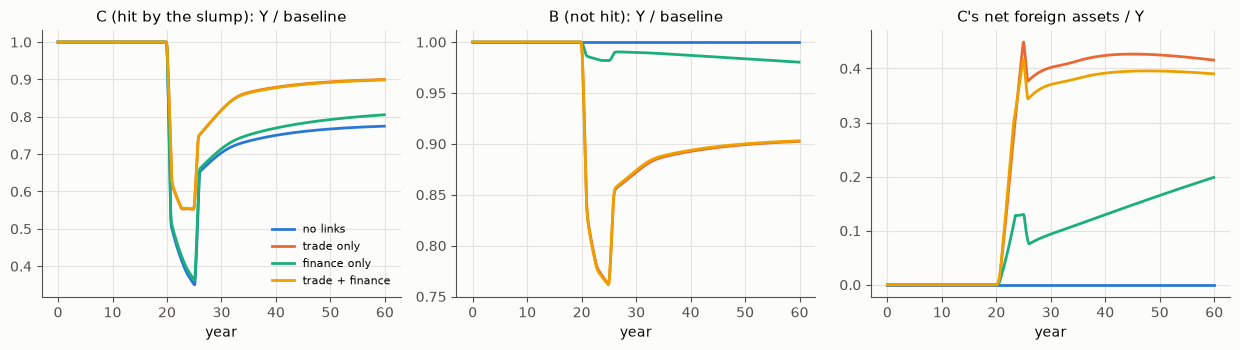

no links         trough C 0.350, trough B 1.000
trade only       trough C 0.553, trough B 0.762
finance only     trough C 0.363, trough B 0.980
trade + finance  trough C 0.553, trough B 0.762


In [8]:
s64 = [0.6, 0.4]
NL64 = neutral_links(s64)
slump = [(20, dict(g0=[-0.02, -0.08]), 1.0), (25, dict(g0=[-0.02, -0.02]), 1.0)]
links = [('no links', dict()),
         ('trade only', dict(m=NL64['m'])),
         ('finance only', dict(hold=NL64['hold'])),
         ('trade + finance', dict(m=NL64['m'], hold=NL64['hold']))]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
res4 = {}
for k, (lab, kw) in enumerate(links):
    b = simulate_world(N=2, T=60, K0=[150, 100], **kw)
    h = simulate_world(N=2, T=60, K0=[150, 100], shocks=slump, **kw)
    res4[lab] = (b, h)
    t = h['t']
    axes[0].plot(t, h['Y'][:, 1] / b['Y'][:, 1], color=PAL[k], label=lab)
    axes[1].plot(t, h['Y'][:, 0] / b['Y'][:, 0], color=PAL[k], label=lab)
    axes[2].plot(t, h['NFA'][:, 1] / h['Y'][:, 1], color=PAL[k], label=lab)
axes[0].set(title='C (hit by the slump): Y / baseline', xlabel='year')
axes[1].set(title='B (not hit): Y / baseline', xlabel='year')
axes[2].set(title="C's net foreign assets / Y", xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
for lab, (b, h) in res4.items():
    print(f"{lab:16s} trough C {np.min(h['Y'][:, 1] / b['Y'][:, 1]):.3f}, trough B {np.min(h['Y'][:, 0] / b['Y'][:, 0]):.3f}")

**図 1**: 左は落ち込みが起きた C、中央は何も起きていない B の所得(基準との比)、右は C の対外純資産。

- つながりがなければ、B は何の影響も受けない。
- **貿易が伝染の主な経路である。** C の需要の落ち込みは、輸入の減少として B に伝わり、B の輸出を減らす。小さい C だけの 5 年間の落ち込みで、大きい B の所得も 2 割以上落ちる。需要が投資を決めるモデルでは、B の投資も落ちた需要に反応するので、伝染が増幅される。
- **金融だけ**でも、C の企業の利潤と配当の落ち込みが、C の資産を持つ B の金利生活者の所得を減らす。ただし、その効果は小さい(B の底は 0.98)。貿易があるところに金融を足しても、差はわずかである。
- 逆に、**C 自身の落ち込みは、つながることで和らぐ**(つながりなしの底 0.35 に対し、貿易でつながると 0.55)。ショックが世界に分け合われるからである。

C は落ち込みの間、輸入が減って経常黒字になり、対外純資産を積み上げる(右図)。

## 5. パラメータの集計: 加重平均と線形の縮約

### 5.1 集計写像

地域をまとめた一国モデル $M_A$ のパラメータを、どう決めればよいか。各パラメータに掛かっている「流れ」で重み付けた平均を取ればよい。

- 労働者の消費性向 $c_w$: 税引き後の賃金で重み付ける。
- 金利生活者の消費性向 $c_r$: 税引き後の利子・配当の受け取りで重み付ける。
- 投資の利潤への反応 $g_1$: 利潤で重み付ける。
- 損耗率 $\delta_0$ や $g_0$: 資本で重み付ける。
- 賃金分配率 ω: 所得で重み付ける。
- 輸入性向 $m$: **まとまりの外からの**輸入を、まとまりの支出で割る。まとまりの中の貿易は、連結すると国内の取引になって消える。
- 保有の行列: まとまりの間の請求権の割合を、残高で重み付けて計算し直す。

重みを流れの大きさにしておくと、連結した時点では、合計の消費・投資・輸入は、一国モデルで計算しても**厳密に**同じになる。これをコードにしたのが `aggregate` である。`state_at` は、ある時点の状態を取り出して、そこから走らせ直すための関数である。

### 5.2 加重平均は結合的(T3)

重みとパラメータの対 $(w,p)$ を考え、二つの対の連結を

$$
(w_1,p_1)\oplus(w_2,p_2)=\Big(w_1+w_2,\ \frac{w_1p_1+w_2p_2}{w_1+w_2}\Big)
$$

と定める。これは可換で、重みが正なら結合的である。さらに、連結したパラメータに重みを掛けると、流れの和をちょうど再現する。だから、集計したパラメータは、まとめる順序によらない。

### 5.3 線形の縮約(T4)

いちばん簡単な場合を考える。閉じた二地域が、それぞれ乗数モデル $Y_i=a_i+b_iY_i$($a_i$ は自律的な需要、$b_i<1$ は所得からの支出の割合)に従うとする。合計の所得は、

$$
Y_1+Y_2 = (a_1+a_2)\cdot\frac{a_1\cdot\frac{1}{1-b_1}+a_2\cdot\frac{1}{1-b_2}}{a_1+a_2}
$$

と書ける。まとめた乗数は、各地域の乗数を**自律需要で重み付けた平均**になる。重み付きの平均なので、T3 により結合的である。

In [9]:
def state_at(w, i):
    """i 期目の始めの状態(再開用)。"""
    st = {k: w[k][i].copy() for k in ('K', 'L', 'B', 'S', 'Pi_e')}
    st['Pi_prev'] = w['Pi'][i - 1].copy() if i > 0 else w['Pi_e'][0].copy()
    return st


def aggregate(w, i, blocks, params, trade, hold):
    """i 期目の流れを重みにして、地域を blocks(添字のリストのリスト)にまとめた粗いモデルのパラメータと状態を返す。

    線形の部分(消費・投資・貿易・利子の受け払い)は、その期について厳密に一致するように重みを選ぶ。
    """
    N = w['Y'].shape[1]
    P = {k: _vec(v, N) for k, v in {**WORLD_DEFAULT, **params}.items() if k not in ('T', 'dt', 'labor_cap')}
    Tm = (np.ones((N, N)) - np.eye(N)) / max(N - 1, 1) if trade is None else np.asarray(trade, float)
    F = np.eye(N) if hold is None else np.asarray(hold, float)
    nb = len(blocks)
    Y, K, L, B, S = (w[k][i] for k in ('Y', 'K', 'L', 'B', 'S'))
    rent, Pi, D, M = w['rent_in'][i], w['Pi'][i], w['D'][i], w['M'][i]
    W = w['omega'][i] * Y
    tb = W + rent                                             # 課税ベース
    wealth = F.T @ (L + B) + S
    Pp = w['Pi'][i - 1] if i > 0 else w['Pi_e'][0]
    def wavg(x, wt, bl):
        return np.sum(x[bl] * wt[bl]) / np.sum(wt[bl])
    agg = {k: np.zeros(nb) for k in ('omega', 'tau', 'c_w', 'c_r', 'c_v', 'v', 'd0', 'g0', 'g1', 'payout', 'm', 'gG')}
    for b, bl in enumerate(blocks):
        agg['omega'][b] = W[bl].sum() / Y[bl].sum()
        agg['tau'][b] = wavg(P['tau'], tb, bl)
        ctA = 1 - agg['tau'][b]
        agg['c_w'][b] = np.sum(P['c_w'][bl] * (1 - P['tau'][bl]) * W[bl]) / (ctA * W[bl].sum())
        agg['c_r'][b] = np.sum(P['c_r'][bl] * (1 - P['tau'][bl]) * rent[bl]) / (ctA * rent[bl].sum())
        agg['c_v'][b] = wavg(P['c_v'], wealth, bl)
        agg['v'][b] = K[bl].sum() / np.sum(K[bl] / P['v'][bl])
        agg['d0'][b] = wavg(P['d0'], K, bl)
        agg['g0'][b] = wavg(P['g0'], K, bl)
        agg['g1'][b] = wavg(P['g1'], np.abs(Pp), bl)
        agg['payout'][b] = wavg(P['payout'], np.abs(Pi), bl)
        agg['gG'][b] = wavg(P['gG'], K / P['v'], bl)
        outside = [j for j in range(N) if j not in bl]
        imp_out = np.sum(M[bl][:, None] * Tm[np.ix_(bl, outside)]) if outside else 0.0
        agg['m'][b] = imp_out / D[bl].sum()
    # ブロック間の貿易行列と保有行列
    TA, FA = np.zeros((nb, nb)), np.zeros((nb, nb))
    cl = L + B
    for J, blJ in enumerate(blocks):
        for I_, blI in enumerate(blocks):
            if I_ != J:
                TA[J, I_] = np.sum(M[blJ][:, None] * Tm[np.ix_(blJ, blI)])
            FA[J, I_] = np.sum(cl[blJ][:, None] * F[np.ix_(blJ, blI)]) / cl[blJ].sum()
        if TA[J].sum() > 0:
            TA[J] /= TA[J].sum()
    st = state_at(w, i)
    stA = {k: np.array([st[k][bl].sum() for bl in blocks]) for k in st}
    pA = {k: v for k, v in params.items() if k not in agg}
    pA.update({k: (v if nb > 1 else float(v[0])) for k, v in agg.items()})
    return pA, TA, FA, stA

In [10]:
%%writefile -a credit_linkage.lean
/-- 重みとパラメータの対。重み `w` は流れの大きさ(所得・資本など)。 -/
structure WP where
  w : ℝ
  p : ℝ

/-- 二つの対の連結: 重みは足し、パラメータは重み付きの平均を取る。 -/
noncomputable def comb (a b : WP) : WP :=
  ⟨a.w + b.w, (a.w * a.p + b.w * b.p) / (a.w + b.w)⟩

/-- T3a: 連結したパラメータは、流れ(重み × パラメータ)の和をちょうど再現する。 -/
theorem comb_flow (a b : WP) (h : a.w + b.w ≠ 0) :
    (comb a b).w * (comb a b).p = a.w * a.p + b.w * b.p := by
  simp only [comb]
  field_simp

/-- T3b: 連結は可換。 -/
theorem comb_comm (a b : WP) : comb a b = comb b a := by
  simp only [comb, WP.mk.injEq]
  constructor <;> ring

/-- T3c: 連結は結合的(重みが正のとき)。 -/
theorem comb_assoc (a b c : WP) (ha : 0 < a.w) (hb : 0 < b.w) (hc : 0 < c.w) :
    comb (comb a b) c = comb a (comb b c) := by
  have h1 : a.w + b.w ≠ 0 := by positivity
  have h2 : b.w + c.w ≠ 0 := by positivity
  have h3 : a.w + b.w + c.w ≠ 0 := by positivity
  have h4 : a.w + (b.w + c.w) ≠ 0 := by positivity
  simp only [comb, WP.mk.injEq]
  constructor
  · ring
  · field_simp
    ring

Appending to credit_linkage.lean


In [11]:
%%writefile -a credit_linkage.lean
/-- T4: 閉じた二地域の乗数モデル Y_i = a_i + b_i Y_i(b_i < 1)を一つにまとめると、
まとめた乗数 1/(1 − b_A) は、各地域の乗数 1/(1 − b_i) を自律需要 a_i で重み付けた平均になる。
重み付きの平均なので、T3 により、まとめる順序によらない。 -/
theorem multiplier_aggregate (a1 a2 b1 b2 : ℝ) (h1 : b1 < 1) (h2 : b2 < 1) (ha : 0 < a1 + a2) :
    a1 / (1 - b1) + a2 / (1 - b2)
      = (a1 + a2) * ((a1 * (1 / (1 - b1)) + a2 * (1 / (1 - b2))) / (a1 + a2)) := by
  have : (1 - b1) ≠ 0 := by linarith
  have : (1 - b2) ≠ 0 := by linarith
  have : a1 + a2 ≠ 0 := ne_of_gt ha
  field_simp

Appending to credit_linkage.lean


数値で確かめる。大きさ 7:3 の二地域(大きさに中立なつながり)で、金利生活者の消費性向だけを 0.25 と 0.6 と違えておく。20 年目の時点で一国に縮約し、その時点の所得の合計が、一国モデルで計算したものと一致するかを見る。

In [12]:
s73 = [0.7, 0.3]
NL73 = neutral_links(s73)
prm = dict(c_r=[0.25, 0.6], m=NL73['m'])
w = simulate_world(N=2, T=120, K0=[175, 75], hold=NL73['hold'], **prm)
i0 = 200
pA, TA, FA, stA = aggregate(w, i0, [[0, 1]], prm, None, NL73['hold'])
a = simulate_world(N=1, T=0.1, state=stA, **pA)
print(f"aggregated c_r = {pA['c_r']:.4f} (weights = rentiers' income), c_w = {pA['c_w']:.4f}, m = {pA['m']:.4f}")
print(f"sum of regional Y at year 20 = {w['Y'][i0].sum():.6f};  Y of the one-region model = {a['Y'][0, 0]:.6f}")

aggregated c_r = 0.3430 (weights = rentiers' income), c_w = 0.9500, m = 0.0000
sum of regional Y at year 20 = 182.685884;  Y of the one-region model = 182.685884


連結した時点では、所得は小数点以下 6 桁まで一致する。二地域の間の貿易は国内の取引になるので、まとめた輸入性向は 0 である。集計した $c_r$ は 0.25 と 0.6 の単純な平均ではない。金利生活者の所得で重み付けた平均で、クロス保有を通じて受け取る利子も重みに入っている。

## 6. 動学の縮約: つながりが構成比を落ち着かせる

### 6.1 一定のパラメータでは、動学は厳密に縮約できない(T5)

連結した時点では厳密でも、時間が経つとずれる。理由は単純である。地域ごとの成長率が違えば、二つの地域の比重(構成比)が動く。比重が動けば、重みも動き、集計したパラメータも動く。

もっと強く言える。離散時間で、二つの地域の大きさが $w_1x^n$ と $w_2y^n$($x\ne y$、$w_1,w_2>0$)で伸びるとする。このとき、その合計は、どんな $c,z$ を選んでも、**一定の率で伸びる一つの量 $c\,z^n$ としては書けない**。

証明は、$n=0,1,2$ の三つの式から

$$
(w_1x+w_2y)^2 = (w_1+w_2)(w_1x^2+w_2y^2)
$$

が出るが、右辺 − 左辺 $= w_1w_2(x-y)^2>0$ で矛盾する、というものである。

In [13]:
%%writefile -a credit_linkage.lean
/-- T5: 伸び率の違う二つの地域の合計は、一定の伸び率で伸びる一つの地域としては書けない。
離散時間で、地域の大きさが w₁ xⁿ と w₂ yⁿ(x ≠ y)なら、どんな c, z でも w₁ xⁿ + w₂ yⁿ = c zⁿ は
すべての n では成り立たない。だから、パラメータが一定の一国モデルで動学を厳密に縮約することはできない。 -/
theorem no_single_exponential (w1 w2 x y : ℝ) (hw1 : 0 < w1) (hw2 : 0 < w2) (hxy : x ≠ y) :
    ¬ ∃ c z : ℝ, ∀ n : ℕ, w1 * x ^ n + w2 * y ^ n = c * z ^ n := by
  rintro ⟨c, z, h⟩
  have h0 := h 0
  have h1 := h 1
  have h2 := h 2
  simp only [pow_zero, mul_one, pow_one] at h0 h1
  have e : (w1 * x + w2 * y) ^ 2 = (w1 + w2) * (w1 * x ^ 2 + w2 * y ^ 2) := by
    rw [h1, h0, h2]; ring
  have key : w1 * w2 * (x - y) ^ 2 = 0 := by linear_combination (-1 : ℝ) * e
  have : 0 < w1 * w2 * (x - y) ^ 2 := by
    have : x - y ≠ 0 := sub_ne_zero.mpr hxy
    positivity
  linarith

Appending to credit_linkage.lean


### 6.2 ところが、つながっていると構成比が落ち着く

T5 は、地域ごとの成長率が**ずっと違い続ける**場合の話である。つながっていない二地域なら、消費性向の違いが成長率の違いになり、構成比は動き続ける。

ところが、貿易と金融でつながっていれば、需要が互いに流れ込むので、成長率がそろっていく。成長率がそろえば、構成比は一定になり、固定した重みの一国モデルで描けるはずである。これを確かめる。

not linked                 error after 10 / 50 / 99 years: -2.30e-03 / -1.58e-02 / -3.84e-02


linked (trade + finance)   error after 10 / 50 / 99 years: +7.18e-08 / +3.59e-07 / +6.26e-07


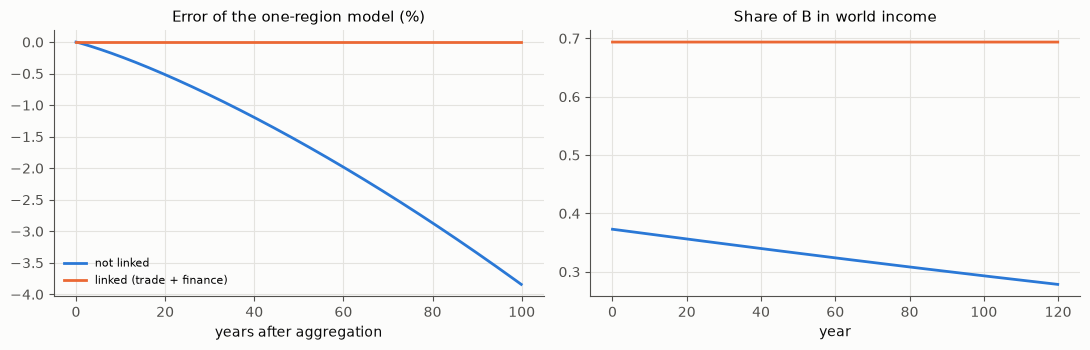

In [14]:
def reduce_compare(prm, links, T=100, K0=(175, 75), t0=20):
    """世界を t0 年目に一国に縮約し、固定したパラメータで T 年走らせて、世界の合計と比べる。"""
    w = simulate_world(N=2, T=t0 + T, K0=list(K0), hold=links.get('hold'), **prm)
    i0 = int(round(t0 / 0.1))
    pA, TA, FA, stA = aggregate(w, i0, [[0, 1]], prm, None, links.get('hold'))
    a = simulate_world(N=1, T=T, state=stA, **pA)
    Ysum = w['Y'][i0:i0 + len(a['Y'])].sum(axis=1)
    return w, a, a['Y'][:, 0] / Ysum - 1, i0


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (lab, links, prm) in enumerate([
        ('not linked', {}, dict(c_r=[0.25, 0.6])),
        ('linked (trade + finance)', NL73, dict(c_r=[0.25, 0.6], m=NL73['m']))]):
    w, a, err, i0 = reduce_compare(prm, links)
    tt = np.arange(len(err)) * 0.1
    axes[0].plot(tt, 100 * err, color=PAL[k], label=lab)
    share = w['Y'][:, 0] / w['Y'].sum(axis=1)
    axes[1].plot(w['t'], share, color=PAL[k], label=lab)
    print(f'{lab:26s} error after 10 / 50 / 99 years: {err[100]:+.2e} / {err[500]:+.2e} / {err[-1]:+.2e}')
axes[0].set(title='Error of the one-region model (%)', xlabel='years after aggregation')
axes[1].set(title="Share of B in world income", xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**図 2**: 左は、20 年目に縮約した一国モデルの所得と、二地域の合計とのずれ(%)。右は、B の比重。

- **つながっていない**場合(青): 金利生活者がよく使う C の方が速く成長し、B の比重が下がり続ける(初期値を決める予備の走行の間にも C が育つので、B の比重は 7 割ではなく 4 割弱から始まる)。ずれは時間とともに育ち、100 年で約 4% になる。
- **つながっている**場合(オレンジ): 需要が互いに流れ込むので成長率がそろい、比重はほとんど動かない。ずれは 100 年たっても $10^{-6}$ 程度にとどまる。

「信用の世界経済は一つ」という直感は、**国々がしっかりつながっていて、平時である限り、ほとんど文字どおりに成り立つ**。T5 が言う「縮約できない」は、つながりの弱い世界、つまり成長率がそろわない世界の話である。

## 7. 非線形の縮約: 折れ目と分布

### 7.1 折れ線の閾値は平均の国では表せない(T6)

前のノートで見たように、モデルには折れ目がある。たとえば、投資が 0 で頭打ちになる、利払いができないと貸倒れが出る、などである。v5 の $\max(0,\Phi-\theta)$ もその一つだった。折れ目があると、平均の国に当てはめた値と、国ごとの値の平均とが一致しない。

$$
\max\Big(0,\ \sum_i w_ix_i\Big) \;\le\; \sum_i w_i\max(0,x_i)\qquad(w_i\ge0)
$$

これはイェンセンの不等式の一つの形で、等号は一般には成り立たない。たとえば、半々の重みで $x=(1,-1)$ なら、左辺は 0、右辺は 1/2 である。

### 7.2 閾値を分布として持てば、連結について閉じる(T8)

では、どうすればよいか。閾値を一つの数ではなく**分布**として持てばよい。各地域が閾値の分布 $\mu_A,\mu_B$ を持つとする。連結した地域の分布は、大きさで重み付けた混合 $(w_A\mu_A+w_B\mu_B)/(w_A+w_B)$ になる。その分布で計算した損失は、各地域の損失の重み付き平均に**ちょうど**等しい。分布の混合は重み付きの平均なので、T3 により結合的である。

つまり、**パラメータの空間を「数」から「分布」に広げれば、モデルの族は連結について閉じる。** 前のノートの第 6.4 節で、企業ごとのばらつきが折れ線の閾値をなめらかな曲線にすることを見た。国の連結でも、同じことが起きている。

In [15]:
%%writefile -a credit_linkage.lean
/-- T6: 折れ線の閾値の集計(イェンセン)。地域ごとの損失 max(0, x_i) を重み付きで足したものは、
平均の地域に当てはめた損失 max(0, Σ w_i x_i) 以上になる。 -/
theorem jensen_max {ι : Type*} (s : Finset ι) (w x : ι → ℝ) (hw : ∀ i ∈ s, 0 ≤ w i) :
    max 0 (∑ i ∈ s, w i * x i) ≤ ∑ i ∈ s, w i * max 0 (x i) := by
  apply max_le
  · exact Finset.sum_nonneg (fun i hi => mul_nonneg (hw i hi) (le_max_left _ _))
  · exact Finset.sum_le_sum (fun i hi => mul_le_mul_of_nonneg_left (le_max_right _ _) (hw i hi))

/-- 等号が成り立たない例: 半々の重みで x = (1, −1) なら、平均の損失は 0 だが、損失の平均は 1/2。 -/
example : max (0 : ℝ) ((1 / 2) * 1 + (1 / 2) * (-1)) < (1 / 2) * max 0 1 + (1 / 2) * max 0 (-1) := by
  norm_num

Appending to credit_linkage.lean


In [16]:
%%writefile -a credit_linkage.lean
/-- T8: 閾値を「分布」として持つと、連結について閉じる。地域 A, B の閾値の分布(有限個の点 θ_k に重み)を
大きさ w_A, w_B で混ぜた分布で計算した損失は、各地域の損失の重み付き平均にちょうど等しい。
分布の混合は重み付きの平均なので、T3 により結合的である。 -/
theorem mixture_loss {K : Type*} (s : Finset K) (θ μA μB : K → ℝ) (Φ wA wB : ℝ) (h : wA + wB ≠ 0) :
    ∑ k ∈ s, ((wA * μA k + wB * μB k) / (wA + wB)) * max 0 (Φ - θ k)
      = (wA * ∑ k ∈ s, μA k * max 0 (Φ - θ k) + wB * ∑ k ∈ s, μB k * max 0 (Φ - θ k)) / (wA + wB) := by
  rw [Finset.mul_sum, Finset.mul_sum, ← Finset.sum_add_distrib, Finset.sum_div]
  apply Finset.sum_congr rfl
  intro k _
  field_simp

end CreditLinkage

Appending to credit_linkage.lean


### 7.3 地域ごとのショックで試す

つながった二地域(6:4、トービンの $q$ への投資の反応 $g_q=0.03$)を 20 年目に一国に縮約する。そのあと、次の三つのショックを与えて、世界の合計(二地域の合計)と一国モデルを比べる。一国モデルに与えるショックは、地域のショックを集計の重みで換算したものである。

1. **C の金利生活者が使わなくなる**($c_r$ を 0.35 → 0.15。線形)。
2. **B だけが楽観に傾き**(リスクプレミアムが 2% → 0.8%)、その後に共通の金利引上げ(3% → 6%)。
3. **C の投資が 5 年間落ち込む**(第 4 節と同じ)。C の投資が 0 で頭打ちになる折れ目にぶつかる。

C's rentiers spend less                max error 0.61%, error at the end +0.61%; trough world 0.869 / one-region 0.875


B boom, then common rate hike          max error 1.04%, error at the end +0.21%; trough world 0.775 / one-region 0.779


C's investment slump (hits the kink)   max error 16.10%, error at the end -0.93%; trough world 0.570 / one-region 0.483


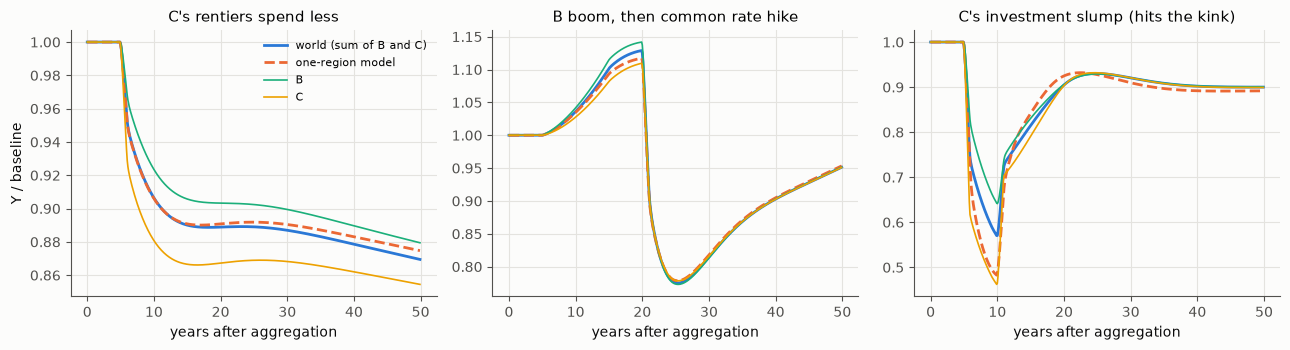

In [17]:
base_prm = dict(m=NL64['m'], g_q=0.03)
w0 = simulate_world(N=2, T=20, K0=[150, 100], hold=NL64['hold'], **base_prm)
i0 = len(w0['t']) - 1
st = w0['final']
pA, TA, FA, stA = aggregate(w0, i0, [[0, 1]], base_prm, None, NL64['hold'])
stA = {k: np.array([st[k].sum()]) for k in st}
wr = w0['rent_in'][i0] / w0['rent_in'][i0].sum()      # 金利生活者の所得の重み
wE = w0['E'][i0] / w0['E'][i0].sum()                  # 株式的富の重み
wK = w0['K'][i0] / w0['K'][i0].sum()                  # 資本の重み
scen7 = [
    ("C's rentiers spend less", [(5, dict(c_r=[0.35, 0.15]), 1.0)],
     [(5, dict(c_r=pA['c_r'] - 0.20 * wr[1]), 1.0)]),
    ('B boom, then common rate hike', [(5, dict(prem=[0.008, 0.02]), 10.0), (20, dict(r_cb=0.06), 1.0)],
     [(5, dict(prem=0.02 - 0.012 * wE[0]), 10.0), (20, dict(r_cb=0.06), 1.0)]),
    ("C's investment slump (hits the kink)", [(5, dict(g0=[-0.02, -0.08]), 1.0), (10, dict(g0=[-0.02, -0.02]), 1.0)],
     [(5, dict(g0=-0.02 - 0.06 * wK[1]), 1.0), (10, dict(g0=-0.02), 1.0)]),
]
wb = simulate_world(N=2, T=50, hold=NL64['hold'], state=st, **base_prm)
ab = simulate_world(N=1, T=50, state=stA, **pA)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, (lab, shW, shA) in zip(axes, scen7):
    w = simulate_world(N=2, T=50, hold=NL64['hold'], state=st, shocks=shW, **base_prm)
    a = simulate_world(N=1, T=50, state=stA, shocks=shA, **pA)
    tt = w['t']
    ax.plot(tt, w['Y'].sum(axis=1) / wb['Y'].sum(axis=1), color=PAL[0], label='world (sum of B and C)')
    ax.plot(tt, a['Y'][:, 0] / ab['Y'][:, 0], color=PAL[1], ls='--', label='one-region model')
    ax.plot(tt, w['Y'][:, 0] / wb['Y'][:, 0], color=PAL[2], lw=1.2, label='B')
    ax.plot(tt, w['Y'][:, 1] / wb['Y'][:, 1], color=PAL[3], lw=1.2, label='C')
    ax.set(title=lab, xlabel='years after aggregation')
    err = a['Y'][:, 0] / w['Y'].sum(axis=1) - 1
    print(f'{lab:38s} max error {np.abs(err).max():.2%}, error at the end {err[-1]:+.2%}; '
          f'trough world {np.min(w["Y"].sum(axis=1) / wb["Y"].sum(axis=1)):.3f} / one-region {np.min(a["Y"][:, 0] / ab["Y"][:, 0]):.3f}')
axes[0].set_ylabel('Y / baseline'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**図 3**: 青が世界の合計、オレンジの破線が一国モデル、細い線が地域ごとの所得で、いずれも基準との比。

- **線形のショック**(左)と、**楽観と金利引上げ**(中央)では、一国モデルは世界の合計にほぼ重なる(ずれは 1% 程度まで)。中央の図では、楽観が B だけで起きたのに、金利を上げた後は C も同じように落ちる。貿易と金融を通じた伝染である。
- **折れ目にぶつかるショック**(右)では、ずれが大きくなる。C の投資は 0 より下には行けないので、C の落ち込みはそこで止まる。ところが、一国モデルの「平均の地域」の投資は 0 にぶつからず、線形のまま落ちる。そのため、一国モデルの方が深く落ち込む(底は世界 0.57 に対して一国モデル 0.48)。これが T6(イェンセン)の実例で、国ごとの損失の平均は、平均の国の損失と一致しない。それでも、落ち込みと回復という定性的な形は一致している。

## 8. 射影

### 8.1 射影してから集計すると元に戻る(T7)

一国モデルで「世界の金利生活者の消費性向が 0.1 下がった」としよう。これを地域のモデルに戻す(射影する)には、地域ごとにどれだけ下げたかを決めなければならない。

配分の重み $\alpha_i$ が $\sum_iw_i\alpha_i=\sum_iw_i$ を満たせば、$p_i\mapsto p_i+\Delta\alpha_i$ と割り振ったときに、集計したパラメータはちょうど $\Delta$ だけ変わる。次の配分は、どれもこの条件を満たす。

- 一様: すべての $\alpha_i=1$。
- 一地域に集中: その地域だけ $\alpha_j=\sum w/w_j$、他は 0。

**射影してから集計すると元に戻る。** ところが、逆は成り立たない。$(1,0)$ を集計すると $1/2$ になり、それを一様に射影すると $(1/2,1/2)$ になって、元に戻らない。集計は多対一だからである。

In [18]:
%%writefile -a credit_linkage.lean
/-- 重み付きの平均(集計)。 -/
noncomputable def agg {ι : Type*} (s : Finset ι) (w p : ι → ℝ) : ℝ :=
  (∑ i ∈ s, w i * p i) / ∑ i ∈ s, w i

/-- T7a: 射影してから集計すると元に戻る。集計した変化 Δ を、配分 α_i(Σ w_i α_i = Σ w_i を満たすもの)で
地域に割り振る(p_i ↦ p_i + Δ α_i)と、集計したパラメータはちょうど Δ だけ変わる。
「一様」(α_i = 1)、「一地域に集中」(α_j = Σw/w_j、他は 0)などは、どれもこの条件を満たす。 -/
theorem agg_proj {ι : Type*} (s : Finset ι) (w p α : ι → ℝ) (Δ : ℝ)
    (hW : ∑ i ∈ s, w i ≠ 0) (hα : ∑ i ∈ s, w i * α i = ∑ i ∈ s, w i) :
    agg s w (fun i => p i + Δ * α i) = agg s w p + Δ := by
  unfold agg
  have : ∑ i ∈ s, w i * (p i + Δ * α i) = ∑ i ∈ s, w i * p i + Δ * ∑ i ∈ s, w i * α i := by
    rw [Finset.mul_sum, ← Finset.sum_add_distrib]
    apply Finset.sum_congr rfl; intro i _; ring
  rw [this, hα]
  field_simp

/-- T7b: 集計してから射影しても、一般には元に戻らない。二地域 p = (1, 0)、重み (1, 1) を集計すると 1/2。
それを一様に射影すると (1/2, 1/2) で、元の (1, 0) とは違う。 -/
example : (fun _ : Fin 2 => agg univ (fun _ => (1 : ℝ)) ![1, 0]) ≠ ![1, 0] := by
  intro h
  have := congrFun h 1
  simp [agg, Fin.sum_univ_two] at this

Appending to credit_linkage.lean


### 8.2 配分の規則で、何が変わるか

大きさ 7:3 の二地域(大きさに中立なつながり)で、世界の $c_r$ を 0.1 下げる変化を、三つの規則で射影する。どの規則でも、集計すると同じ変化になる。

uniform   aggregated c_r = 0.250; at year 75: world 0.855, B 0.855, C 0.855, C NFA/Y -0.00
all in B  aggregated c_r = 0.250; at year 75: world 0.852, B 0.848, C 0.862, C NFA/Y -0.47


all in C  aggregated c_r = 0.250; at year 75: world 0.841, B 0.852, C 0.815, C NFA/Y +1.25


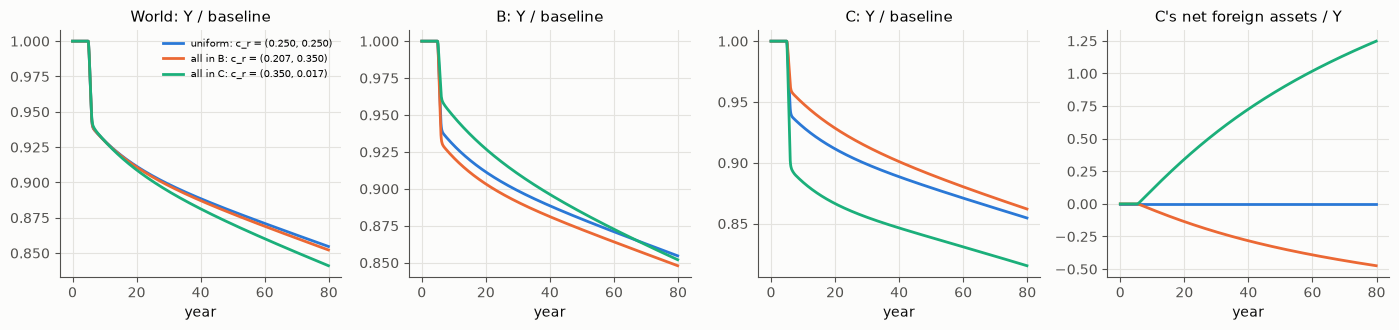

In [19]:
base8 = dict(c_r=[0.35, 0.35], m=NL73['m'])
w0 = simulate_world(N=2, T=20, K0=[175, 75], hold=NL73['hold'], **base8)
i0 = len(w0['t']) - 1
st8 = w0['final']
wt = w0['rent_in'][i0] / w0['rent_in'][i0].sum()
wb8 = simulate_world(N=2, T=80, hold=NL73['hold'], state=st8, **base8)
D = -0.1
rules = {'uniform': np.array([D, D]), 'all in B': np.array([D / wt[0], 0.0]), 'all in C': np.array([0.0, D / wt[1]])}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True)
for k, (lab, dv) in enumerate(rules.items()):
    cr = 0.35 + dv
    w = simulate_world(N=2, T=80, hold=NL73['hold'], state=st8, shocks=[(5, dict(c_r=list(cr)), 1.0)], **base8)
    tt = w['t']
    lab2 = f'{lab}: c_r = ({cr[0]:.3f}, {cr[1]:.3f})'
    axes[0].plot(tt, w['Y'].sum(axis=1) / wb8['Y'].sum(axis=1), color=PAL[k], label=lab2)
    axes[1].plot(tt, w['Y'][:, 0] / wb8['Y'][:, 0], color=PAL[k])
    axes[2].plot(tt, w['Y'][:, 1] / wb8['Y'][:, 1], color=PAL[k])
    axes[3].plot(tt, w['NFA'][:, 1] / w['Y'][:, 1], color=PAL[k])
    print(f'{lab:9s} aggregated c_r = {wt @ cr:.3f}; at year 75: world {w["Y"][-1].sum() / wb8["Y"][-1].sum():.3f}, '
          f'B {w["Y"][-1, 0] / wb8["Y"][-1, 0]:.3f}, C {w["Y"][-1, 1] / wb8["Y"][-1, 1]:.3f}, C NFA/Y {w["NFA"][-1, 1] / w["Y"][-1, 1]:+.2f}')
for ax, ttl in zip(axes, ['World: Y / baseline', 'B: Y / baseline', 'C: Y / baseline', "C's net foreign assets / Y"]):
    ax.set(title=ttl, xlabel='year')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**図 4**: 世界の所得(左)は、三つの規則でほとんど同じになる。ところが、地域ごとの所得と、C の対外純資産(右)は規則しだいで大きく違う。

- C だけが使わなくなれば、C の所得は大きく落ち、C は貯めたお金で外国の資産を買う債権国になる。
- B だけが使わなくなれば、逆に C は債務国になる。

**射影は、世界全体については無害だが、地域の配分と貸し借りについては、配分の規則そのものが仮定になる。** 「世界の消費性向が下がった」と言うだけでは、どこの国が困るのかは決まらない。

## 9. 結合性と、国家の統合・分裂

### 9.1 三地域で確かめる結合性

大きさ 5:3:2 の三地域(消費性向と投資の反応を地域ごとに違えておく)を、次の三通りで一つにまとめる。

- 一度にまとめる。
- B と C を先にまとめ、それから D とまとめる:$(B\oplus C)\oplus D$。
- C と D を先にまとめ、それから B とまとめる:$B\oplus(C\oplus D)$。

二段階でまとめるときは、途中でできた二地域のモデルを 1 期だけ走らせ、その流れを重みにして、もう一度集計する。

In [20]:
s3 = [0.5, 0.3, 0.2]
NL3 = neutral_links(s3)
prm3 = dict(c_r=[0.25, 0.45, 0.6], g1=[0.7, 0.75, 0.8], m=NL3['m'])
w3 = simulate_world(N=3, T=40, K0=list(250 * np.array(s3)), trade=NL3['trade'], hold=NL3['hold'], **prm3)
i0 = 200
p_once, *_ = aggregate(w3, i0, [[0, 1, 2]], prm3, NL3['trade'], NL3['hold'])
results = {'all at once': p_once}
for lab, blocks in [('(B+C)+D', [[0, 1], [2]]), ('B+(C+D)', [[0], [1, 2]])]:
    p2, T2, F2, s2 = aggregate(w3, i0, blocks, prm3, NL3['trade'], NL3['hold'])
    w2 = simulate_world(N=2, T=0.1, trade=T2, hold=F2, state=s2, **p2)
    results[lab], *_ = aggregate(w2, 0, [[0, 1]], p2, T2, F2)
print('parameter      all at once        (B+C)+D            B+(C+D)')
for k in ['c_w', 'c_r', 'g1', 'omega', 'tau', 'd0', 'payout']:
    print(f'{k:10s} ' + '  '.join(f'{float(results[r][k]):.12f}' for r in results))

parameter      all at once        (B+C)+D            B+(C+D)
c_w        0.950000000000  0.950000000000  0.950000000000
c_r        0.369709031369  0.369709031401  0.369709031517
g1         0.734482658539  0.734482663554  0.734482666709
omega      0.650000000000  0.650000000000  0.650000000000
tau        0.250000000000  0.250000000000  0.250000000000
d0         0.050000000000  0.050000000000  0.050000000000
payout     0.600000000000  0.600000000000  0.600000000000


三通りの集計は、10 桁ほどまで一致する(わずかなずれは、途中のモデルを 1 期走らせるときの数値誤差)。重みが足し算で積み上がるので、集計の順序によらない。T1 と T3 の数値での確認である。

### 9.2 国家の統合と分裂

国家の数が増えたり減ったりすることは、このモデルでは「どの部門を連結するか」を変えることに当たる。ここまでの地域は、すでに通貨と中央銀行を共有している(通貨統合)。この節では、さらに**財政**を統合する場合を考える。

- **財政が別々**: 各地域の政府が、自分の赤字を自分の国債で賄う。国債の比率が高くなると増税する財政ルールを持つ。
- **財政統合**: 全地域の赤字を合算し、新しい国債を所得の比率で割り振る(過去の国債は各地域に残る)。差額は地域間の財政移転になり、経常収支に入る。財政ルールは、統合全体の国債比率を見る。
- **統合の後に分裂**: 40 年目に財政統合を解消する。

C だけが 5 年間の投資の落ち込みに見舞われる(第 4 節と同じ)。

separate budgets         trough C 0.448, trough B 0.665, C public debt/Y at year 39 1.82, at year 79 1.61


fiscal union             trough C 0.458, trough B 0.652, C public debt/Y at year 39 2.07, at year 79 1.79


union, split at year 40  trough C 0.458, trough B 0.652, C public debt/Y at year 39 2.07, at year 79 1.69


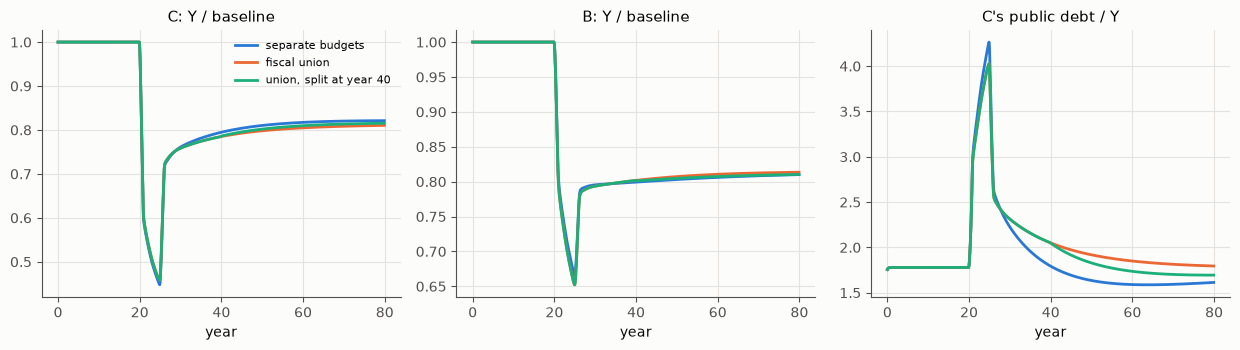

In [21]:
cfg9 = dict(N=2, T=80, K0=[150, 100], m=NL64['m'], hold=NL64['hold'], fiscal=0.03, b_target=1.5)
b9 = simulate_world(**cfg9)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
for k, (lab, fu) in enumerate([('separate budgets', None), ('fiscal union', (0, 1000)),
                                ('union, split at year 40', (0, 40))]):
    w = simulate_world(shocks=slump, fiscal_union=fu, **cfg9)
    tt = w['t']
    axes[0].plot(tt, w['Y'][:, 1] / b9['Y'][:, 1], color=PAL[k], label=lab)
    axes[1].plot(tt, w['Y'][:, 0] / b9['Y'][:, 0], color=PAL[k], label=lab)
    axes[2].plot(tt, w['B'][:, 1] / w['Y'][:, 1], color=PAL[k], label=lab)
    print(f"{lab:24s} trough C {np.min(w['Y'][:, 1] / b9['Y'][:, 1]):.3f}, trough B {np.min(w['Y'][:, 0] / b9['Y'][:, 0]):.3f}, "
          f"C public debt/Y at year 39 {w['B'][390, 1] / w['Y'][390, 1]:.2f}, at year 79 {w['B'][-1, 1] / w['Y'][-1, 1]:.2f}")
axes[0].set(title='C: Y / baseline', xlabel='year'); axes[1].set(title='B: Y / baseline', xlabel='year')
axes[2].set(title="C's public debt / Y", xlabel='year'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**図 5**: 財政統合は、C の落ち込みをわずかに和らげ、その分 B の落ち込みをわずかに深くする。統合すると、C が増税を迫られる圧力が、統合全体に分散されるからである。効果が小さいのは、このモデルの政府支出が生産能力に比例するだけで、景気に逆らって支出を増やす仕組みがないためである。

40 年目に分裂させると、所得の動きは連続のままである。不連続に変わるのは国債の割り振り(右図)だけである。

**国家の統合と分裂は、部門の連結のしかたを変える操作として、モデルの中で連続的に扱える。** 国家を「パラメータ」として埋め込むのでは、この操作は表せない。国家を「貸借を持つ部門」として埋め込めば、表せる。

## 10. 中核と周辺

### 10.1 累積的因果を埋め込む

JRF のレポート「[Matcha を使った neuro-symbolic な法的推論とウォーラーステイン理論](https://github.com/JRF-2018/wallerstein_theory)」の Sim 1 では、累積的因果のモデルで中核・半周辺・周辺が生まれることを見た。累積的因果は Myrdal (1957) や Kaldor (1970) の考え方で、Krugman and Venables (1995) と同じ型である。そこでは、輸送費が下がると対称な状態が崩れ、グローバル化とともに中核が 10 → 5 → 3 → 2 → 1 と統合されていった。

ここでは、同じ型の仕組みを信用循環モデルに埋め込み、**縮約したときに何が見えなくなるか**を確かめる。理論には深入りしない。

- **貿易の配分(重力型)**: 地域 $j$ の支出のうち地域 $i$ から買う割合を、$S_{ij}\propto K_i\,A_i^{\theta}\,\phi^{[i\ne j]}$ とする。$K_i$ は生産能力、$A_i$ は競争力、$\phi$ は貿易の自由度(0 なら交易なし、1 なら貿易の費用なし)、$\theta=5$ である。
- **競争力の動き**:
$$
\frac{d\ln A_i}{dt} = v\,(g_i-\bar g) - \chi\,(u_i-\bar u) - \eta\ln A_i
$$
  - 第 1 項: 速く成長する地域ほど学習して競争力が伸びる(フェルドーン則。累積的因果の源)。
  - 第 2 項: 売れずに設備が遊んでいる地域は、賃金や価格が下がって競争力を取り戻す(安定化の力。$\chi=0.5$)。
  - 第 3 項: 技術は拡散して、差は少しずつ縮む($\eta=0.05$)。

### 10.2 分岐

対称な二地域で、B の競争力だけを 1% 高くして始める。300 年後の B の比重を、累積的因果の強さ $v$ と貿易の自由度 $\phi$ を変えて見る。

phi=0.2: 0.518 0.529 0.547 0.987 0.986 0.993 0.991 0.993 0.996


phi=0.5: 0.516 0.525 0.541 0.974 0.974 0.983 0.986 0.988 0.991


phi=0.8: 0.512 0.518 0.529 0.554 0.971 0.973 0.977 0.971 0.983


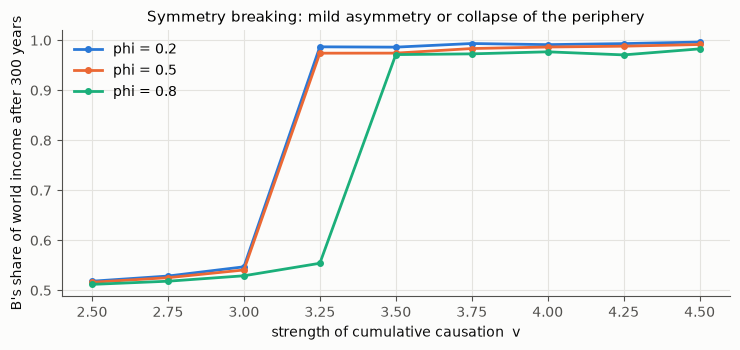

In [22]:
vs = np.arange(2.5, 4.51, 0.25)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for k, phi in enumerate([0.2, 0.5, 0.8]):
    shares = []
    for v in vs:
        w = simulate_world(N=2, T=300, K0=[125, 125], phi_trade=phi, A0=[1.01, 1.0], verdoorn=v, price_adj=0.5, init=None)
        shares.append(w['Y'][-1, 0] / w['Y'][-1].sum())
    ax.plot(vs, shares, color=PAL[k], marker='o', ms=4, label=f'phi = {phi}')
    print(f'phi={phi}: ' + ' '.join(f'{x:.3f}' for x in shares))
ax.set(xlabel='strength of cumulative causation  v', ylabel="B's share of world income after 300 years",
       title='Symmetry breaking: mild asymmetry or collapse of the periphery')
ax.legend(); plt.tight_layout(); plt.show()

**図 6**: 累積的因果の強さ $v$ が閾値(およそ 3.1〜3.4)を超えると、B の比重は一気にほぼ 1(0.97〜0.99)になる。つまり、周辺 C はほとんど消えてしまう。閾値より下では、穏やかな非対称にとどまる。貿易の自由度 $\phi$ が高いほど、閾値はわずかに上がる。

Sim 1 と違い、このモデルには「周辺を支える床」がない。Sim 1 の一次産業の所得や、Sim 2 の労働余剰に当たるものである。そのため、中間で安定する中核と周辺は現れず、「穏やかな非対称」か「周辺の消滅」かの二択になる。もう一つ、需要が投資を決めるモデルを地域でつなぐと、競争力の差がなくても、価格による調整がなければ地域は分かれていく。大きい地域ほど多く売れて利潤が増え、さらに資本が増えるからである。**需要主導の信用循環そのものが、累積的因果を持っている。**

### 10.3 構造的な格差がある世界を縮約する

次に、はじめから格差のある世界を考える。

- 周辺 C は、競争力が 1 割低い。
- C の借入のスプレッドは 3%(B は 1%)。
- C の企業と政府への請求権の 4 割を、中核 B の金利生活者が持つ。
- 累積的因果は、閾値より十分に弱くしておく($v=1$)。

この世界を 200 年走らせ、100 年目で一国に縮約して、残りの 100 年を比べる。

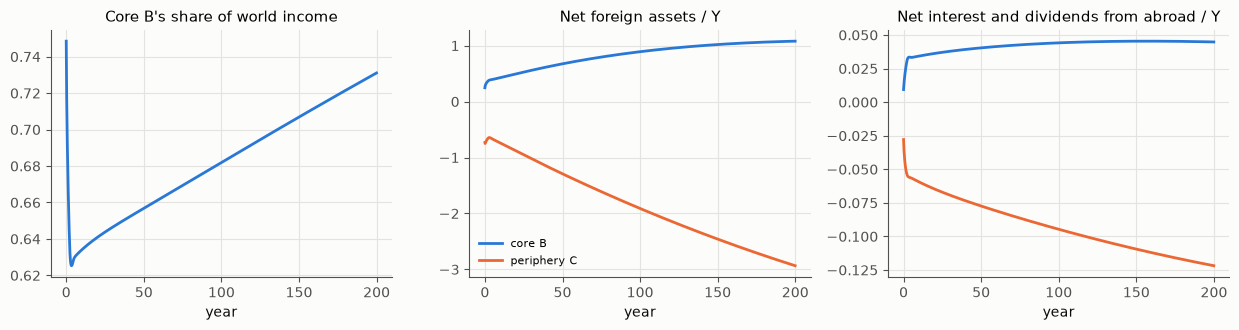

B's share: year 0 0.749, year 100 0.682, year 200 0.731; growth B 0.0346, C 0.0321
C pays abroad (net) 12.2% of its income
one-region model from year 100 (spread 0.0158): error after 10 / 50 / 99 years -0.018% / -0.188% / -0.582%


In [23]:
Hcp = np.array([[0.95, 0.05], [0.40, 0.60]])
prm10 = dict(verdoorn=1.0, price_adj=0.5, spread=[0.01, 0.03])
w = simulate_world(N=2, T=200, K0=[150, 100], phi_trade=0.5, A0=[1.0, 0.9], hold=Hcp, init=None, **prm10)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4), sharex=True)
axes[0].plot(w['t'], w['Y'][:, 0] / w['Y'].sum(axis=1), color=PAL[0])
axes[0].set(title="Core B's share of world income", xlabel='year')
for k, (j, lab) in enumerate([(0, 'core B'), (1, 'periphery C')]):
    axes[1].plot(w['t'], w['NFA'][:, j] / w['Y'][:, j], color=PAL[k], label=lab)
    axes[2].plot(w['t'], (w['rent_in'][:, j] - w['pay'][:, j]) / w['Y'][:, j], color=PAL[k], label=lab)
axes[1].set(title='Net foreign assets / Y', xlabel='year')
axes[2].set(title='Net interest and dividends from abroad / Y', xlabel='year')
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
i0 = 1000
spA = np.average([0.01, 0.03], weights=w['L'][i0])
pA, TA, FA, stA = aggregate(w, i0, [[0, 1]], {**prm10, 'm': w['m'][i0]}, None, Hcp)
pA['spread'] = spA
for k in ('verdoorn', 'price_adj'):
    pA.pop(k, None)
a = simulate_world(N=1, T=100, state=stA, **pA)
err = a['Y'][:, 0] / w['Y'][i0:i0 + 1000].sum(axis=1) - 1
print(f"B's share: year 0 {w['Y'][0, 0] / w['Y'][0].sum():.3f}, year 100 {w['Y'][i0, 0] / w['Y'][i0].sum():.3f}, "
      f"year 200 {w['Y'][-1, 0] / w['Y'][-1].sum():.3f}; growth B {w['g'][-1, 0]:.4f}, C {w['g'][-1, 1]:.4f}")
print(f"C pays abroad (net) {-(w['rent_in'][-1, 1] - w['pay'][-1, 1]) / w['Y'][-1, 1]:.1%} of its income")
print(f"one-region model from year 100 (spread {spA:.4f}): error after 10 / 50 / 99 years "
      f"{err[100]:+.3%} / {err[500]:+.3%} / {err[-1]:+.3%}")

**図 7**: 最初の数年の跳ねは、格差のない状態から始めたための調整である。その後、周辺 C の比重は、ゆっくりと下がり続ける(左)。C は外国(B)に対して大きな債務を負い(中央)、所得の 1 割以上を利子・配当として B に払い続ける(右)。貿易の不等価交換とは別の、**金融の形をとった不等価交換**である。

注意: この結果は、累積的因果が閾値から離れていることに頼っている。たとえば $v=2$ にすると、同じ格差のもとで周辺 C はほぼ消えてしまう。格差のある世界は、閾値の近くでは小さな違いで運命が分かれる。

ところが、この世界を 100 年目で一国に縮約すると、その後 100 年の世界全体の所得は、1% 未満のずれで描ける(最後の出力)。**縮約した一国モデルは全体を正しく描くが、内側の格差は見えなくなる。** 世界を一つの経済として見る見方は、全体については正しい。けれども、その内側で誰が誰に払い続けているかは、分解しないと見えない。

## 11. 通貨が別々のとき

### 11.1 何が加わるか

ここまでは通貨が共通だった。通貨が別々になると、次のことが加わる。

- **為替レート** $e$。ここでは通貨 1 の価値を通貨 0 で測ったものとする。
- 各地域の量は、自国通貨で測る。地域の間の流れ(貿易・利子)は、$e$ で換算する。
- 輸入は相対価格に反応する(輸入の価格弾力性 η)。自国通貨が安くなると、輸入品は高くなり、輸出品は安くなる。
- 外国に持っている資産の値打ちは、為替で変わる(評価効果)。

**はじめに、この節の限界をはっきり書いておく。** このモデルには物価がない。だから、為替が動けば、それがそのまま国と国の財の相対価格(実質為替レート)の変化になり、ずっと残る。現実には、切り下げると輸入品の値段が上がり、賃金や物価がそれを追いかける。そのため、切り下げの効果は時間とともに薄れていく。このモデルには、その調整がない。

為替がどう決まるかも、本当は資産市場と期待の問題で、このモデルにはそれもない。だから、**この節の数値は、為替の効果の大きさや持続性を示すものではない。** 言えるのは、次の二つだけである。

- どういう向きの仕組みがあるか(11.2 節、11.4 節)。
- 通貨が別々の世界を縮約するには何が要るか(11.3 節)。こちらはモデルの構造から言えることで、物価がないことに左右されない。

以下では、主に**固定相場で、平価を変更する(切り下げる)場合**を扱う。為替を自由に動かす場合は、11.4 節で検討として扱う。

### 11.2 切り下げは、自分を助け、隣を沈める

C が 5 年間の投資の落ち込みに見舞われる(第 4 節と同じ)。その最中に、C が自国通貨を 1 年かけて 30% 切り下げる場合と、通貨統合のままの場合を比べる(η = 1)。

currency union               trough C 0.553, trough B 0.762, max |sector-balance error| 1e-13


C devalues 30% (fixed rate)  trough C 0.922, trough B 0.564, max |sector-balance error| 1e-13


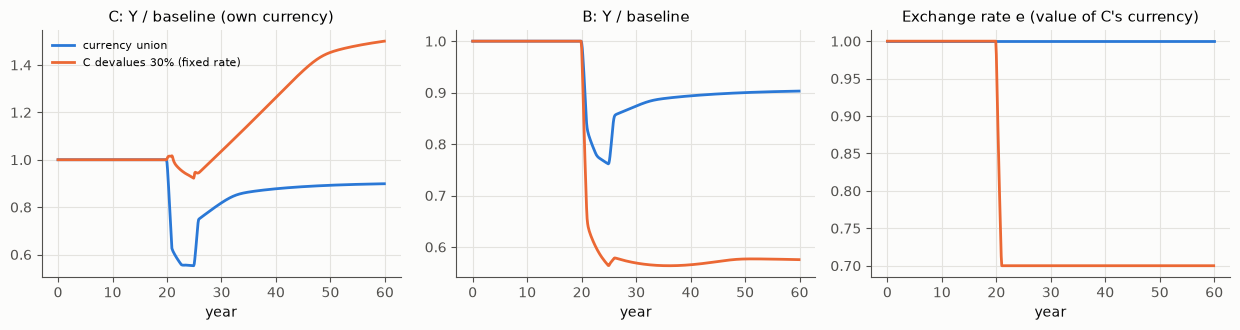

In [24]:
cfg11 = dict(N=2, T=60, K0=[150, 100], m=NL64['m'], hold=NL64['hold'])
b11 = simulate_world(**cfg11)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4), sharex=True)
for k, (lab, fx) in enumerate([('currency union', None),
                               ('C devalues 30% (fixed rate)',
                                dict(currency=[0, 1], regime='fixed', eta=1.0, shifts=[(20, 0.7, 1.0)]))]):
    w = simulate_world(shocks=slump, fx=fx, **cfg11)
    tt = w['t']
    axes[0].plot(tt, w['Y'][:, 1] / b11['Y'][:, 1], color=PAL[k], label=lab)
    axes[1].plot(tt, w['Y'][:, 0] / b11['Y'][:, 0], color=PAL[k], label=lab)
    axes[2].plot(tt, w['e'][:, 0], color=PAL[k], label=lab)
    print(f"{lab:28s} trough C {np.min(w['Y'][:, 1] / b11['Y'][:, 1]):.3f}, trough B {np.min(w['Y'][:, 0] / b11['Y'][:, 0]):.3f}, "
          f"max |sector-balance error| {np.abs(w['sb_err']).max():.0e}")
axes[0].set(title='C: Y / baseline (own currency)', xlabel='year')
axes[1].set(title='B: Y / baseline', xlabel='year')
axes[2].set(title="Exchange rate e (value of C's currency)", xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**図 8**: 切り下げると、C の財が B から見て安くなる。C の輸出が伸び、C の落ち込みは和らぐ(左)。その代わり、B は需要を C に奪われて落ち込む(中央)。いわゆる**近隣窮乏化**である。

この図から読み取ってよいのは、**向き**だけである。切り下げは、自分の不況の一部を相手に押し出す。11.1 節で述べたとおり、このモデルでは物価が調整されないので、30% の切り下げが恒久的な競争力の差として残り続ける。だから、C がその後ずっと基準を上回り、B がずっと沈んだままになるのは、モデルの欠落から来る誇張である。物価が調整されれば、どちらも時間とともに基準へ戻っていくはずである。

通貨が別々なら、地域は自分の不況を為替で外に押し出せる。通貨統合では、それができない代わりに、ショックが共有される。これは、Mundell (1961) の最適通貨圏の論点の一つの側面である。

### 11.3 為替は縮約に新しい状態変数を持ち込む

共通通貨の世界と、切り下げのある世界を、それぞれ 15 年目に一国に縮約して比べる。どちらも、縮約した後に C の投資の落ち込みが起きる。一国モデルの所得は、通貨 0 建てで測った世界の合計と比べる。

In [25]:
w0 = simulate_world(N=2, T=15, K0=[150, 100], hold=NL64['hold'], m=NL64['m'])
i0 = len(w0['t']) - 1
st11 = w0['final']
pA, TA, FA, stA = aggregate(w0, i0, [[0, 1]], dict(m=NL64['m']), None, NL64['hold'])
stA = {k: np.array([st11[k].sum()]) for k in st11}
wK = w0['K'][i0] / w0['K'][i0].sum()
slump15 = [(5, dict(g0=[-0.02, -0.08]), 1.0), (10, dict(g0=[-0.02, -0.02]), 1.0)]
a = simulate_world(N=1, T=45, state=stA, shocks=[(5, dict(g0=-0.02 - 0.06 * wK[1]), 1.0), (10, dict(g0=-0.02), 1.0)], **pA)
for lab, fx in [('common currency', None),
                ('C devalues 10% (eta = 1)', dict(currency=[0, 1], regime='fixed', eta=1.0, shifts=[(5, 0.9, 1.0)]))]:
    w = simulate_world(N=2, T=45, hold=NL64['hold'], m=NL64['m'], state=st11, shocks=slump15, fx=fx)
    Ynum = (w['Y'] * w['cv']).sum(axis=1)
    err = a['Y'][:, 0] / Ynum - 1
    print(f'{lab:26s} error of the one-region model: max {np.abs(err).max():.1%}, at the end {err[-1]:+.1%}')

common currency            error of the one-region model: max 7.8%, at the end +0.9%
C devalues 10% (eta = 1)   error of the one-region model: max 12.5%, at the end +5.5%


共通通貨でも、C の投資が 0 で頭打ちになる折れ目のせいで、途中のずれは小さくない(第 7 節の右の図と同じ現象)。それでも、最後にはずれはほぼ消える。切り下げがあると、ずれは最後まで残る。一国モデルは為替というものを持たないからである。

**通貨が別々の世界を縮約するには、為替(と各通貨建ての資産・負債の構成)を、追加の状態変数として持たなければならない。**

なお、新興国のように、自国通貨では外国から借りられず、外貨建てで借りるしかない場合がある。Eichengreen and Hausmann (1999) が「原罪」と呼んだ状態である。このとき切り下げは、外貨建ての債務を自国通貨で測って膨らませ、助けになるどころか危機を深くする。会計を閉じる手間が大きいので、この簡略版のモデルには入れていない。

### 11.4 検討: 為替を自由に動かすと、なぜ乱れるのか

最初は、為替を「経常収支が黒字なら通貨高」という規則で動かしてみた。すると為替が大きく動き、不況の国がさらに沈んだ。原因は、**利子が外に出ていくことではなく、この規則の向き**にあった。

需要が所得を決めるモデルでは、**不況の国ほど輸入が減って、経常収支が黒字になる**。そこに「黒字なら通貨高」の規則を当てはめると、不況の国の通貨が上がる。その結果、輸出が減ってさらに不況が深まる、という逆向きの自己強化が起きる。

そこで、為替が景気の差(稼働率の差)に反応する規則、つまり不況の国の通貨が下がる規則に差し替えて、C だけの 5 年間の不況(第 4 節と同じ)で比べる。

currency union                         trough C 0.553, trough B 0.762, e between 1.000 and 1.000


floating, reacts to current account    trough C 0.355, trough B 0.864, e between 1.000 and 1.297


floating, reacts to utilization gap    trough C 0.588, trough B 0.724, e between 0.930 and 1.085


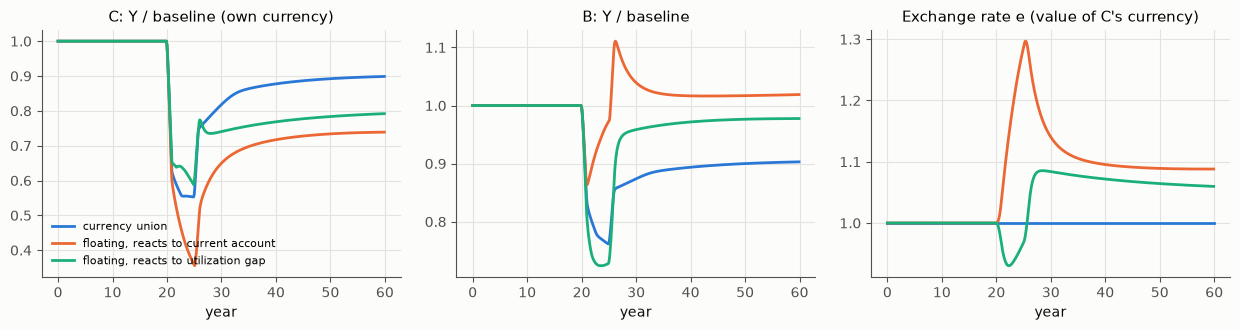

In [26]:
cfg11f = dict(N=2, T=60, K0=[150, 100], m=NL64['m'], hold=NL64['hold'])
b11f = simulate_world(**cfg11f)
rules11 = [('currency union', None),
           ('floating, reacts to current account', dict(currency=[0, 1], regime='float', eta=1.5, k_ca=1.0, k_r=0.0)),
           ('floating, reacts to utilization gap', dict(currency=[0, 1], regime='float', eta=1.5, k_ca=0.0, k_r=0.0, k_u=0.5))]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4), sharex=True)
for k, (lab, fx) in enumerate(rules11):
    w = simulate_world(shocks=slump, fx=fx, **cfg11f)
    tt = w['t']
    axes[0].plot(tt, w['Y'][:, 1] / b11f['Y'][:, 1], color=PAL[k], label=lab)
    axes[1].plot(tt, w['Y'][:, 0] / b11f['Y'][:, 0], color=PAL[k], label=lab)
    axes[2].plot(tt, w['e'][:, 0], color=PAL[k], label=lab)
    print(f"{lab:38s} trough C {np.min(w['Y'][:, 1] / b11f['Y'][:, 1]):.3f}, trough B {np.min(w['Y'][:, 0] / b11f['Y'][:, 0]):.3f}, "
          f"e between {w['e'][:, 0].min():.3f} and {w['e'][:, 0].max():.3f}")
axes[0].set(title='C: Y / baseline (own currency)', xlabel='year')
axes[1].set(title='B: Y / baseline', xlabel='year')
axes[2].set(title="Exchange rate e (value of C's currency)", xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**図 9**: 経常収支に反応させると(オレンジ)、不況の C の通貨が上がり、C は通貨統合のとき(青)よりも深く沈む。稼働率の差に反応させると(緑)、不況の C の通貨が下がり、C の落ち込みは通貨統合のときより浅くなる。為替の動きも小さい。その分、B の落ち込みは通貨統合のときよりやや深くなる(切り下げと同じく、不況の一部が相手に押し出される)。

ここから言えるのは、「為替という仕組みそのものが悪い」ということではない、ということである。**為替が何に反応して動くかが決定的**である。ただし、緑の規則でも、回復した後に C の通貨がやや高くなりすぎ、長い目で見ると C の水準は通貨統合のときより低くなる。11.1 節で述べたとおり、物価と期待のないこのモデルでは、この差の大きさには意味がない。

現実の変動相場は、経常収支よりも、資本の移動と期待で動くことが知られている。為替がファンダメンタルズからかなり離れて動くことも、長く議論されてきた。改善策として考えられてきたものは、たとえば次のとおりである。

- 為替が景気の差に沿って動くよう、金融政策や為替介入で管理する(管理変動相場)。
- 黒字国にも赤字国にも調整の負担を課す。ケインズが構想した国際清算同盟は、黒字国にも課金する仕組みで、「不況の国が黒字になる」という非対称に直接答えようとしたものと読める。
- 短期の資本移動を管理する。

どれがよいかを論じるには、物価・賃金の調整と、資産市場の期待をモデルに入れる必要がある。それは今後の課題である。

## 12. v5 をもう一度読む

前のノートの第 13.3 節では、利子・配当の一部を国外の債権者に払う一国経済を考えた。払う割合を 100% にすると、改良モデルは「利子が経済から消える」v5 と同じ構造になった。多地域モデルでは、このことをもう少し正確に言える。地域 C の企業と政府への請求権を、すべて B の金利生活者が持つ場合を、大きさに中立なつながりの場合と比べる。

In [27]:
H0 = NL64['hold']
for lab, Hc in [('claims held as in neutral links', H0), ("all of C's claims held by B", np.array([H0[0], [1.0, 0.0]]))]:
    w = simulate_world(N=2, T=100, K0=[150, 100], m=NL64['m'], hold=Hc, init=None)
    print(f"{lab:32s} growth B {w['g'][-1, 0]:.4f}, C {w['g'][-1, 1]:.4f}; B's share {w['Y'][-1, 0] / w['Y'][-1].sum():.3f}; "
          f"C: public debt/Y {w['B'][-1, 1] / w['Y'][-1, 1]:.2f}, NFA/Y {w['NFA'][-1, 1] / w['Y'][-1, 1]:+.2f}, "
          f"net interest and dividends paid abroad / Y {-(w['rent_in'][-1, 1] - w['pay'][-1, 1]) / w['Y'][-1, 1]:.1%}")

claims held as in neutral links  growth B 0.0343, C 0.0343; B's share 0.600; C: public debt/Y 1.71, NFA/Y -0.00, net interest and dividends paid abroad / Y 0.0%


all of C's claims held by B      growth B 0.0343, C 0.0342; B's share 0.647; C: public debt/Y 4.73, NFA/Y -4.20, net interest and dividends paid abroad / Y 22.2%


C は所得の 2 割以上を利子・配当として B に払い続ける。国債の比率も対外債務も大きく膨らむ。それでも、C の成長率は B と同じに保たれ、崩壊はしない。払った利子の一部が、B の金利生活者の消費を通じて、C の輸出として戻ってくるからである。

v5 の崩壊は、利子が **世界のどこにも戻らない** ことから来ていた。v5 を「信用の世界経済」のモデルとして読むなら、利子は世界のどこかで誰かの所得になっていなければならない。そこを戻した上で地域に分けると、v5 が描こうとした「利払いの重さ」は、崩壊ではなく、**中核と周辺の間の持続的な支払いの流れ**として現れる。

## 13. まとめ: 問いへの答え

**問い 1: 国家も企業に類するプレイヤーとして、信用の世界経済に複数「埋め込める」か。**

埋め込める。ただし、パラメータとしてではなく、**貸借を持つ部門として**埋め込む必要がある。会計の面では、国家は企業と同じく単位であり、連結決算と同じ要領で、合算と相殺ができる(T1, T2)。国家が企業と違うのは、次の三点である。

- 税を取ること。
- 国債の利子が誰かの所得になること。
- 通貨と制度の境界を決めること。

**問い 2: 大小の国のモデル $M_B$, $M_C$ をつないだ経済を、一国のモデル $M_A$ として描けるか。**

三つの層で答えが違う。

| 層 | 答え | 根拠 |
|---|---|---|
| 会計 | 厳密に描ける | T1, T2(Lean) |
| 線形の行動(その時点) | 厳密に描ける。パラメータは流れで重み付けた平均 | T3, T4(Lean)、第 5 節 |
| 動学 | 一般には描けない。ただし、つながった世界では成長率がそろうので、平時はほぼ厳密。釣り合いの取れた成長経路の上では厳密 | T5(Lean)、第 6 節。釣り合い経路の上での厳密な縮約は、モデルの式そのものについて Lean で証明した(下の注) |
| 非線形・地域ごとのショック | 近似。定性的には一致する。閾値を分布として持てば、連結について閉じる | T6, T8(Lean)、第 7 節 |
| 通貨が別々 | 為替を追加の状態変数として持つ必要がある(物価と期待のないこの簡略版では、為替の効果の大きさは論じられない) | 第 11 節 |

**注: モデル全体についての定理。** この文書の Lean(第 15 節)は、連結や集計の部品についての補題である。それとは別に、リポジトリ [credit_simulation_v6](https://github.com/JRF-2018/credit_simulation_v6) では、多地域のモデルの 1 期の写像そのものを Lean で書き、次の三つを証明した(第 14 節に主張を載せる)。

- **定理 A**: その写像は規模について 1 次同次で、地域ごとのパラメータが違っていても、釣り合いの取れた成長経路の上では、一度一致した一国のモデルは世界の合計とその後ずっと一致する。
- **定理 B**: 線形の核では、つながっていれば構成比は釣り合い経路の比重へ幾何級数的に近づき、つながっていなければ動き続ける。
- **定理 C**: 一国のモデルのずれは、「地域の成長率のばらつき」と「構成比の動き」の積で上から抑えられる。

第 6 節で、つながった世界のずれが 100 年たっても $10^{-6}$ 程度にとどまったのは、定理 B のとおり構成比が釣り合い経路に近づき、定理 A・C のとおりその上でのずれが消えていくからである。

**問い 3: $M_B$, $M_C$ のパラメータの変化に対応する $M_A$ の変化を規定できるか。逆に射影できるか。**

規定できる。重み付きの平均の変化として決まる。逆の射影は一つに決まらず、配分の規則を選ぶと決まる。射影してから集計すると元に戻るが、集計してから射影しても元に戻らない(T7)。世界全体の結果はほとんど規則によらないが、国ごとの結果と貸し借りは規則しだいで大きく変わる(第 8 節)。

**問い 4: 連結は半群になるか。**

単純な二項演算の半群にはならない。$(B\oplus C)$ と $D$ をつなぐには、$D$ と $B$、$D$ と $C$ の取引を別々に知る必要があるからである。正しい構造は、**単位の分け方(分割)と、それを粗くする写像の合成**である。T1 が、その合成が整合すること(段階的に連結しても一度に連結しても同じ)を保証する。パラメータの側では、(重み, パラメータ) の対が可換モノイドになる(T3)。

**問い 5: 国家が増えたり減ったりするとき、企業間・国家間に構造格差があるとき、モデルではどうなるか。**

- **国家の統合・分裂**は、どの部門を連結するかを変える操作として、連続的に扱える。所得の動きは連続で、変わるのは債務の割り振りである(第 9 節)。
- **構造格差**は、パラメータの持続的な偏りとして入る。需要主導の信用循環は、それ自体が累積的因果を持つ。安定化の力が弱いと、周辺は消えてしまう(第 10 節)。
- 格差のある世界を縮約しても、全体はよく描ける。ただし、周辺から中核への持続的な支払いの流れは見えなくなる。

### 残る問い

- **物価と為替の期待**: 為替を意味のある形で扱うには、物価・賃金の調整と、資産市場の期待を入れる必要がある。物価の調整を入れれば、切り下げの効果は時間とともに薄れるはずである。為替がどんな規則で動けば安定するか(第 11.4 節)も、そのうえで改めて問うべきである。
- **周辺を支える床**: 一次産業の所得や労働余剰を入れれば、Sim 1 のような「中間で安定する中核と周辺」が現れるはずである。
- **原罪**: 外貨建ての借入を入れて、切り下げが危機を深くする場合を扱う。
- **景気に逆らう財政**: 政府支出が失業に反応するなら、財政統合の効果はずっと大きくなるはずである。

## 14. モデル全体についての定理: 定理 A・B・C

### 14.1 部品の補題と、モデル全体の定理

この文書の Lean(第 15 節でチェックする `credit_linkage.lean`)が示しているのは、連結や集計の**部品**についての性質である。結合性、加重平均、イェンセンの不等式などで、どれもモデルの式そのものには触れていない。だから、「多地域のモデルが、条件つきで一国のモデルに縮約できる」ということは、そこからは出てこない。

そこで、リポジトリ [credit_simulation_v6](https://github.com/JRF-2018/credit_simulation_v6) では、**多地域のモデルの 1 期の写像そのもの**を Lean で書き、それについて定理を証明した。ここには、その定義と定理の主張だけを載せる。証明は `-- 証明は省略` として省いた。全文と証明はリポジトリの `CreditV6/` にある。CI で毎回ビルドしており、`sorry`(証明の省略)は一つもない。

| ファイル | 内容 |
|---|---|
| `Model.lean` | モデルの 1 期の写像(`work_link` の `simulate_world` の書き写し) |
| `Homogeneity.lean` | その写像が規模について 1 次同次であること |
| `Reduction.lean`、`TheoremA.lean` | 定理 A: 釣り合い経路の上での厳密な縮約 |
| `TheoremB.lean` | 定理 B: 線形の核で、つながりが構成比を落ち着かせる |
| `TheoremC.lean` | 定理 C: 一国のモデルのずれの上限 |

### 14.2 モデルを Lean で書く

`Model.lean` は、第 3 節の多地域のモデル(共通通貨、労働の天井なし、財政統合なし、競争力による貿易配分なし)の 1 期の計算を、Python 版と同じ順序で書き写したものである。Python 版がゼロ除算を避けるために置いている下限(資本 ≥ 10⁻³ など)だけは省いた。

所得 $Y$ は、生産能力の上限込みの方程式 $Y=\mathrm{softmin}(Z(CY+a),\,Y_p)$ の解として定義した。Python 版はこれを反復法で解いているが、Lean では「解がただ一つあればそれ」として定義している。

状態(`State`)には、規模とともに伸びる量(資本・債務・期待利潤など、1 次の量)と、比率(貸倒れ率・稼働率、0 次の量)がある。「規模を c 倍する」作用 `State.act` は、1 次の量だけを c 倍する。

<details><summary>Model.lean の全文(定義だけで、証明はない)</summary>

```lean
import Mathlib
import CreditV6.Reduction

/-!
# 多地域の信用循環モデルの 1 期の写像

`python/world.py` の `simulate_world` の 1 期の計算を、そのまま Lean に書き写したもの。
対象は、続編のノート(credit_linkage.ipynb)の第 3〜9 節で使った範囲である:

* 通貨は共通(`fx` なし)、財政統合なし、労働の天井なし、競争力による貿易配分なし、パラメータのショックなし。
* 財政ルール(`fiscal`)は含む。
* Python 版でゼロ除算を避けるために置いている下限(資本 ≥ 10⁻³、所得 ≥ 10⁻⁹、借入残高 ≥ 10⁻⁶ での割り算)は
  省く。状態が正の範囲にあるとき、両者は一致する。

所得 `Y` は、生産能力の上限込みの方程式 `Y = softmin(Z(C Y + a), Y_p)` の解として定義する(`Ysol`)。
Python 版はこれを反復法で解いている。ここでは、解がただ一つあるときはそれを、そうでなければ 0 を取る。
-/

open Finset BigOperators Real

namespace CreditV6

/-- 地域ごとの量。 -/
abbrev Vec (N : ℕ) := Fin N → ℝ

/-- `min(a, b)` のなめらか版(幅 `w`)。Python の `softmin` と同じ。 -/
noncomputable def softmin (a b w : ℝ) : ℝ := -w * log (exp (-a / w) + exp (-b / w))

/-- `max(0, a)` のなめらか版(幅 `w`): `w · log(1 + exp(a/w))`。Python の `w * np.logaddexp(0, a / w)` と同じ。 -/
noncomputable def softplus (a w : ℝ) : ℝ := w * log (exp 0 + exp (a / w))

/-- モデルのパラメータ(地域ごと)と、地域の間の構造。 -/
structure Params (N : ℕ) where
  dt : ℝ
  v : Vec N
  u_max : Vec N
  omega : Vec N
  d0 : Vec N
  kappa : Vec N
  c_w : Vec N
  c_r : Vec N
  c_v : Vec N
  payout : Vec N
  tau : Vec N
  gG : Vec N
  fiscal : Vec N
  b_target : Vec N
  r_cb : Vec N
  spread : Vec N
  spread_loss : Vec N
  rho : Vec N
  g0 : Vec N
  g1 : Vec N
  g2 : Vec N
  g_q : Vec N
  q_ref : Vec N
  prem : Vec N
  lam : Vec N
  T_adj : Vec N
  default_share : Vec N
  tau_e : Vec N
  m : Vec N
  /-- `trade j i`: 地域 j の輸入のうち地域 i から買う割合。 -/
  trade : Fin N → Fin N → ℝ
  /-- `hold j i`: 地域 j の企業・政府への請求権のうち、地域 i の金利生活者が持つ割合。 -/
  hold : Fin N → Fin N → ℝ

/-- モデルの状態。前半は規模とともに伸びる量(1 次)、後半は比率(0 次)。 -/
@[ext]
structure State (N : ℕ) where
  K : Vec N
  L : Vec N
  B : Vec N
  S : Vec N
  Pi_e : Vec N
  Pi_prev : Vec N
  E_prev : Vec N
  Y_prev : Vec N
  loss : Vec N
  u_prev : Vec N

/-- 規模の作用: 1 次の量だけを c 倍する。 -/
def State.act {N : ℕ} (c : ℝ) (x : State N) : State N where
  K := c • x.K
  L := c • x.L
  B := c • x.B
  S := c • x.S
  Pi_e := c • x.Pi_e
  Pi_prev := c • x.Pi_prev
  E_prev := c • x.E_prev
  Y_prev := c • x.Y_prev
  loss := x.loss
  u_prev := x.u_prev

instance {N : ℕ} : Scaling (State N) where
  act := State.act
  act_mul := by intro a b x; simp [State.act, smul_smul]
  act_one := by intro x; simp [State.act]

section quantities
variable {N : ℕ} (p : Params N) (x : State N)

/-- 資本で決まる生産能力 `K/v` と、上限込みの能力 `u_max K/v`。 -/
noncomputable def Yk : Vec N := fun i => x.K i / p.v i
noncomputable def Yp : Vec N := fun i => p.u_max i * Yk p x i

/-- 貸出金利(0 次)。 -/
noncomputable def rL : Vec N := fun i =>
  (p.r_cb i + p.spread i) / (1 - p.rho i) + p.spread_loss i * min (x.loss i) 0.1

/-- 株式的富: 期待利潤をなめらかに正にして(幅は資本の 0.1%)、割引率で割る。 -/
noncomputable def Eq : Vec N := fun i =>
  softplus (x.Pi_e i) (0.001 * x.K i) / (softplus (rL p x i + p.prem i) 0.005 + 0.005)

/-- 株式的富の目減りによる損耗の増幅(0 次)。 -/
noncomputable def delta : Vec N := fun i =>
  p.d0 i * (1 + p.kappa i * (max 0 (-(Eq p x i - x.E_prev i) / x.E_prev i) / p.dt))

/-- 純投資率の希望(0 次)。 -/
noncomputable def gnet : Vec N := fun i =>
  p.g0 i + p.g1 i * x.Pi_prev i / x.K i + p.g2 i * (x.u_prev i - 0.85) + p.g_q i * (Eq p x i / x.K i - p.q_ref i)

noncomputable def Ides : Vec N := fun i => x.K i * max 0 (p.d0 i + gnet p x i)
noncomputable def retained : Vec N := fun i => (1 - p.payout i) * x.Pi_prev i + p.d0 i * x.K i
noncomputable def dLraw : Vec N := fun i =>
  softmin (Ides p x i - retained p x i) ((p.lam i * (Eq p x i + x.K i) - x.L i) / p.T_adj i) (0.01 * x.K i)
noncomputable def Inv : Vec N := fun i => max 0 (dLraw p x i + retained p x i)
noncomputable def dL : Vec N := fun i => Inv p x i - retained p x i
noncomputable def Gov : Vec N := fun i => p.gG i * Yp p x i / p.u_max i

/-- 財政ルールで動く税率(0 次)。 -/
noncomputable def tauE : Vec N := fun i =>
  max 0 (min (p.tau i + p.fiscal i * (x.B i / x.Y_prev i - p.b_target i)) 0.8)

noncomputable def ct : Vec N := fun i => 1 - tauE p x i

/-- 所得に依らない利子・配当の部分(支払う側 j)。 -/
noncomputable def flow0 : Vec N := fun j =>
  rL p x j * x.L j + p.r_cb j * x.B j + p.payout j * (-p.d0 j * x.K j - rL p x j * x.L j)

noncomputable def wealth : Vec N := fun i => (∑ j, p.hold j i * (x.L j + x.B j)) + x.S i

/-- 需要のうち所得に依らない部分 `a`。 -/
noncomputable def avec : Vec N := fun i =>
  p.c_r i * ct p x i * ((∑ j, p.hold j i * flow0 p x j) + p.r_cb i * x.S i)
    + p.c_v i * wealth p x i + Inv p x i + Gov p x i

/-- 支出 `D = C Y + a`(所得 `Y` を与えたとき)。 -/
noncomputable def Dvec (Y : Vec N) : Vec N := fun i =>
  p.c_w i * ct p x i * p.omega i * Y i
    + p.c_r i * ct p x i * (∑ j, p.hold j i * (p.payout j * (1 - p.omega j) * Y j))
    + avec p x i

/-- `Z[i, j]`: 地域 j の支出のうち地域 i の生産になる割合。 -/
def Zm (i j : Fin N) : ℝ := (if i = j then 1 - p.m j else 0) + p.trade j i * p.m j

/-- 実際の所得のもとでの需要(生産の側から見たもの) `Z (C Y + a)`。 -/
noncomputable def demand (Y : Vec N) : Vec N := fun i => ∑ j, Zm p i j * Dvec p x Y j

/-- 所得の方程式: `Y = softmin(Z(C Y + a), Y_p)`(幅は能力の 1%)。 -/
def eqY (Y : Vec N) : Prop := ∀ i, Y i = softmin (demand p x Y i) (Yp p x i) (0.01 * Yp p x i)

open Classical in
/-- 所得: 方程式の解がただ一つあればそれ、なければ 0。 -/
noncomputable def Ysol : Vec N := if h : ∃! Y, eqY p x Y then h.exists.choose else 0

end quantities

section step
variable {N : ℕ} (p : Params N) (x : State N)

noncomputable def Yv : Vec N := Ysol p x
noncomputable def Pi : Vec N := fun i => (1 - p.omega i) * Yv p x i - p.d0 i * x.K i - rL p x i * x.L i
noncomputable def pay : Vec N := fun j => rL p x j * x.L j + p.r_cb j * x.B j + p.payout j * Pi p x j
noncomputable def rentIn : Vec N := fun i => (∑ j, p.hold j i * pay p x j) + p.r_cb i * x.S i
noncomputable def Wage : Vec N := fun i => p.omega i * Yv p x i
noncomputable def consDes : Vec N := fun i =>
  p.c_w i * ct p x i * Wage p x i + p.c_r i * ct p x i * rentIn p x i + p.c_v i * wealth p x i
noncomputable def Ddes : Vec N := fun i => consDes p x i + Inv p x i + Gov p x i
/-- 財が行き渡る割合(0 次)。 -/
noncomputable def rhoS : Vec N := fun i => Yv p x i / demand p x (Yv p x) i
/-- `purch i j`: 地域 j が実際に地域 i から買う額。 -/
noncomputable def purch (i j : Fin N) : ℝ := Zm p i j * Ddes p x j * rhoS p x i
noncomputable def Dreal : Vec N := fun j => ∑ i, purch p x i j
noncomputable def Imp : Vec N := fun j => Dreal p x j - purch p x j j
noncomputable def Exp : Vec N := fun i => (∑ j, purch p x i j) - purch p x i i
noncomputable def tax : Vec N := fun i => tauE p x i * (Wage p x i + rentIn p x i)
noncomputable def CA : Vec N := fun i => Exp p x i - Imp p x i + (rentIn p x i - pay p x i)
noncomputable def CF : Vec N := fun i => (1 - p.omega i) * Yv p x i - rL p x i * x.L i
noncomputable def default : Vec N := fun i =>
  min (p.default_share i * max 0 (-CF p x i)) (0.5 * x.L i)
noncomputable def dB : Vec N := fun i => Gov p x i + p.r_cb i * x.B i - tax p x i
noncomputable def newIss : Vec N := fun i => dL p x i + dB p x i
noncomputable def portOut : Vec N := fun i => (∑ j, p.hold j i * newIss p x j) - newIss p x i
noncomputable def dS : Vec N := fun i => CA p x i - portOut p x i

/-- **1 期の写像**(`simulate_world` のループの 1 回分)。 -/
noncomputable def step : State N where
  K := fun i => x.K i + (Inv p x i - delta p x i * x.K i) * p.dt
  L := fun i => max 0 (x.L i + (dL p x i - default p x i) * p.dt)
  B := fun i => x.B i + dB p x i * p.dt
  S := fun i => x.S i + dS p x i * p.dt
  Pi_e := fun i => x.Pi_e i + (Pi p x i - x.Pi_e i) / p.tau_e i * p.dt
  Pi_prev := Pi p x
  E_prev := Eq p x
  Y_prev := Yv p x
  loss := fun i => default p x i / x.L i
  u_prev := fun i => Yv p x i / Yk p x i

end step

end CreditV6
```

</details>

### 14.3 モデルの写像は 1 次同次である

モデルの量を一つずつ、「c 倍になる」か「変わらない」かで確かめていくと、写像全体が 1 次同次であることが示せる(`step_hom`)。

鍵になるのは次の二つである。

- **なめらかな min・max の幅も規模に比例させてあること**(`softmin_smul`)。前のノートのモデルでは、株式的富の式のなめらかさの幅だけが絶対値だったので、この定理のために資本に比例させた。数値はほとんど変わらない。
- **所得の方程式が同次で、解がただ一つなら、解も同次になること**(`Ysol_act`)。

割り算は、どれも $(c\,a)/(c\,b)=a/b$ の形になるので、状態が正であることは仮定しなくてよい。


```lean
variable {c : ℝ} (hc : 0 < c)
include hc
variable {N : ℕ} (x : State N) (c : ℝ)
variable {N : ℕ} (p : Params N) (x : State N) {c : ℝ} (hc : 0 < c)
include hc

lemma softmin_smul (a b w : ℝ) : softmin (c * a) (c * b) (c * w) = c * softmin a b w := by
  ...  -- 証明は省略

/-- 所得(方程式のただ一つの解)も同次。 -/
lemma Ysol_act : Ysol p (x.act c) = c • Ysol p x := by
  ...  -- 証明は省略

/-- **モデルの 1 期の写像は、規模について 1 次同次である。** -/
theorem step_hom {N : ℕ} (p : Params N) : HomS (step p) := by
  ...  -- 証明は省略
```

### 14.4 定理 A: 釣り合い経路の上での厳密な縮約

骨格は抽象的な定理である。世界の写像 $F$ と一国の写像 $G$ がともに規模について 1 次同次で、まとめる写像 $S$ が規模の作用と可換だとする。このとき、釣り合い経路の上($F x_0 = \gamma\cdot x_0$)で一度一致すれば($G(Sx_0)=S(Fx_0)$)、その後ずっと一致する。誤差があるときは、$G$ がリプシッツ連続なら、そのずれの育ち方に上限がある。


```lean
/-- **定理 A(作用の形)**: 世界の写像 `F` と一国モデルの写像 `G` が作用について 1 次同次で、
まとめる写像 `S` が作用と可換なら、釣り合い経路の上で一度一致すれば、ずっと一致する。 -/
theorem exact_reduction_on_ray_S {X A : Type*} [Scaling X] [Scaling A]
    (F : X → X) (G : A → A) (S : X → A) (hF : HomS F) (hG : HomS G)
    (hS : ∀ c : ℝ, 0 < c → ∀ x, S (Scaling.act c x) = Scaling.act c (S x))
    (x₀ : X) (γ : ℝ) (hγ : 0 < γ) (hray : F x₀ = Scaling.act γ x₀) (hone : G (S x₀) = S (F x₀)) :
    ∀ n : ℕ, G^[n] (S x₀) = S (F^[n] x₀) := by
  ...  -- 証明は省略

/-- **定理 A(誤差つき)**: その時点での一致に誤差 `ε · ‖S x₀‖` があり、`G` がリプシッツ定数 `L` を持つなら、
n 期後のずれは `ε · ‖S x₀‖ · Σ_{k<n} L^k γ^{n-1-k}` 以下である。 -/
theorem approx_reduction_on_ray {X A : Type*} [AddCommGroup X] [Module ℝ X]
    [NormedAddCommGroup A] [NormedSpace ℝ A]
    (F : X → X) (G : A → A) (S : X →ₗ[ℝ] A) (hF : Hom1 F) (hG : Hom1 G)
    (L : ℝ) (hL : 0 ≤ L) (hLip : ∀ a b, ‖G a - G b‖ ≤ L * ‖a - b‖)
    (x₀ : X) (γ : ℝ) (hγ : 0 < γ) (hray : F x₀ = γ • x₀)
    (ε : ℝ) (hone : ‖G (S x₀) - S (F x₀)‖ ≤ ε * ‖S x₀‖) :
    ∀ n : ℕ, ‖G^[n] (S x₀) - S (F^[n] x₀)‖
      ≤ ε * ‖S x₀‖ * ∑ k ∈ Finset.range n, L ^ k * γ ^ (n - 1 - k) := by
  ...  -- 証明は省略
```



これを、実際のモデルに当てはめる。まとめる写像 `aggState` は、1 次の量は地域の合計、0 次の量は 1 次の量で重み付けた平均にする(貸倒れ率は借入残高で、稼働率は資本で)。一国のモデルは、同じ式の 1 地域版 `step pA` である。


```lean
/-- 世界の状態を、一国の状態にまとめる。 -/
noncomputable def aggState (x : State N) : State 1 where
  K := fun _ => ∑ i, x.K i
  L := fun _ => ∑ i, x.L i
  B := fun _ => ∑ i, x.B i
  S := fun _ => ∑ i, x.S i
  Pi_e := fun _ => ∑ i, x.Pi_e i
  Pi_prev := fun _ => ∑ i, x.Pi_prev i
  E_prev := fun _ => ∑ i, x.E_prev i
  Y_prev := fun _ => ∑ i, x.Y_prev i
  loss := fun _ => wavg x.L x.loss
  u_prev := fun _ => wavg x.K x.u_prev

/-- **定理 A**: 釣り合い経路の上では、一度一致した一国のモデルは、世界の合計とずっと一致する。
地域ごとのパラメータは違ってよい。 -/
theorem world_reduction (p : Params N) (pA : Params 1) (x₀ : State N) (γ : ℝ) (hγ : 0 < γ)
    (hray : step p x₀ = x₀.act γ) (hone : step pA (aggState x₀) = aggState (step p x₀)) :
    ∀ n : ℕ, (step pA)^[n] (aggState x₀) = aggState ((step p)^[n] x₀) := by
  ...  -- 証明は省略
```



**地域ごとのパラメータ `p` は違っていてよい。** 仮定「ある時点で一致する」(`hone`)は、第 5 節の `aggregate` が流れを重みにしてパラメータを作ることで(なめらかな min・max の効き方の違いを除いて)満たしている。

### 14.5 定理 B: つながりが構成比を落ち着かせる

定理 A は「世界が釣り合い経路の上にあれば」という定理である。では、世界は釣り合い経路に近づくのか。第 6 節では、つながっていれば構成比が落ち着くことを数値で見た。これを、モデルの「線形の核」で証明する。

金融(借入・国債)を外し、需要の式と投資の式だけを残すと、二つの地域の資本は 1 期ごとに 2×2 の行列で動く。

- 対角の成分 $a, d$ は、自分の資本が自分の次の期の資本を生む分である。
- 非対角の成分 $b, c$ は、貿易を通じて相手の需要が自分の投資を生む分である。

**つながっていなければ $b=c=0$、つながっていれば $b, c>0$。**

つながっているとき、固有値は二つの実数 $\lambda_1>|\lambda_2|$ になる。状態を「釣り合い経路の方向 $v_1$」と「ずれの方向 $v_2$」に分けると、ずれの係数と釣り合い経路の係数の比は、毎期ちょうど $\lambda_2/\lambda_1$ 倍になる。つながっていないときは、二つの資本が $a^n$, $d^n$ で別々に伸び、構成比は $(d/a)^n$ 倍で動き続ける。


```lean
variable (A : M2)
variable (hb : 0 < A.b) (hc : 0 < A.c)
include hb hc

/-- 釣り合い経路の方向とずれの方向に分けた状態は、それぞれの固有値の冪で伸びる。 -/
theorem iterate_decomp (α β : ℝ) (n : ℕ) :
    (step A)^[n] (α • v1 A + β • v2 A) = (α * lam1 A ^ n) • v1 A + (β * lam2 A ^ n) • v2 A := by
  ...  -- 証明は省略

/-- `λ₁ > |λ₂|`(つながりがあり、`a + d > 0` のとき)。 -/
theorem lam_gap (had : 0 < A.a + A.d) : |lam2 A| < lam1 A := by
  ...  -- 証明は省略

/-- **定理 B**: ずれの係数と釣り合い経路の係数の比は、毎期ちょうど `λ₂/λ₁` 倍になる。 -/
theorem deviation_ratio (had : 0 < A.a + A.d) (α β : ℝ) (n : ℕ) :
    (β * lam2 A ^ n) / (α * lam1 A ^ n) = (β / α) * (lam2 A / lam1 A) ^ n := by
  ...  -- 証明は省略

/-- 減衰の率 `|λ₂/λ₁|` は 1 より小さい。 -/
theorem rate_lt_one (had : 0 < A.a + A.d) : |lam2 A / lam1 A| < 1 := by
  ...  -- 証明は省略

/-- つながっていないとき(`b = c = 0`)、二つの資本は `aⁿ`, `dⁿ` で別々に伸びる。
`a ≠ d` なら、資本の比 `K_C/K_B` は `(d/a)ⁿ` 倍になり、構成比は動き続ける。 -/
theorem unlinked_iterate (hb : A.b = 0) (hc : A.c = 0) (x : ℝ × ℝ) (n : ℕ) :
    (step A)^[n] x = (A.a ^ n * x.1, A.d ^ n * x.2) := by
  ...  -- 証明は省略

theorem unlinked_ratio (hb : A.b = 0) (hc : A.c = 0) (ha : A.a ≠ 0) (x : ℝ × ℝ) (hx : x.1 ≠ 0) (n : ℕ) :
    ((step A)^[n] x).2 / ((step A)^[n] x).1 = (A.d / A.a) ^ n * (x.2 / x.1) := by
  ...  -- 証明は省略
```



減衰の率 $|\lambda_2/\lambda_1|$ は、つながり $bc$ が大きいほど小さくなる($\lambda_1-\lambda_2=\sqrt{(a-d)^2+4bc}$ が大きくなるから)。実際の(非線形の)モデルでも同じことが起きるかを、数値で確かめる。

パラメータの同じ二地域を、大きさに中立なつながり(比重 6:4 を想定)でつなぐ。資本の配分だけを 7.5:2.5 にずらして始め、構成比のずれが半分になるまでの年数を、つながりの強さ $k$ を変えて測る。

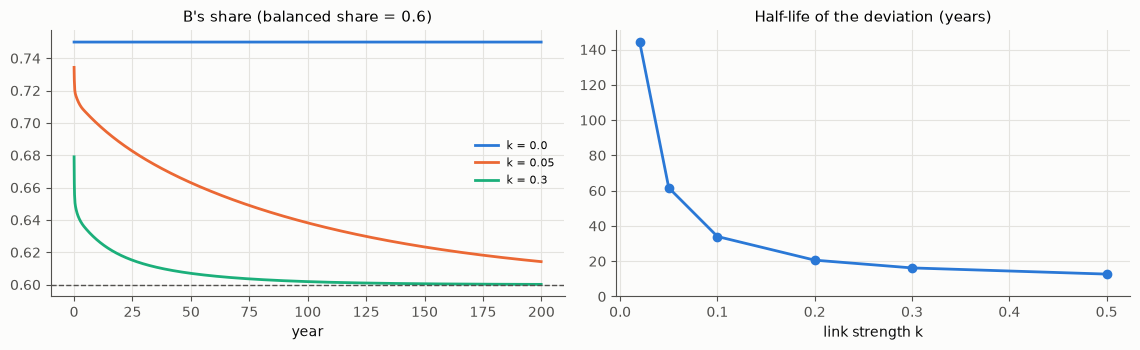

k = 0.00: does not converge
k = 0.02: half-life  144.5 years
k = 0.05: half-life   61.6 years
k = 0.10: half-life   34.0 years
k = 0.20: half-life   20.6 years
k = 0.30: half-life   16.2 years
k = 0.50: half-life   12.7 years


In [28]:
ks = [0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
half = []
for k in ks:
    kw = {}
    if k > 0:
        NLk = neutral_links([0.6, 0.4], k)
        kw = dict(m=NLk['m'], hold=NLk['hold'])
    w = simulate_world(N=2, T=200, K0=[187.5, 62.5], init=None, **kw)
    sh = w['Y'][:, 0] / w['Y'].sum(axis=1)
    dev = np.abs(sh - 0.6)
    idx = np.where(dev[50:] < dev[50] / 2)[0]      # 5 年目のずれが半分になるまで(最初の調整を除く)
    half.append(idx[0] * 0.1 if len(idx) else np.inf)
    if k in (0.0, 0.05, 0.3):
        axes[0].plot(w['t'], sh, label=f'k = {k}', color=PAL[[0.0, 0.05, 0.3].index(k)])
axes[0].axhline(0.6, color=INK2, lw=1, ls='--')
axes[0].set(title="B's share (balanced share = 0.6)", xlabel='year'); axes[0].legend(fontsize=8)
kk = [k for k, h in zip(ks, half) if np.isfinite(h)]
axes[1].plot(kk, [h for h in half if np.isfinite(h)], marker='o', color=PAL[0])
axes[1].set(title='Half-life of the deviation (years)', xlabel='link strength k', ylim=(0, None))
plt.tight_layout(); plt.show()
for k, h in zip(ks, half):
    print(f'k = {k:4.2f}: half-life {h:6.1f} years' if np.isfinite(h) else f'k = {k:4.2f}: does not converge')

**図 10**: 左は B の比重。つながりがなければ(青、$k=0$)、比重は 0.75 のまま動かない(パラメータが同じなので成長率が同じで、ずれたまま固定される)。つながると、比重は釣り合い経路の 0.6 に近づく(オレンジ、緑)。右は、ずれが半分になるまでの年数で、つながりが強いほど短い。実際のモデルでも、定理 B の線形の核と同じことが起きている。

### 14.6 定理 C: 一国のモデルのずれの上限

一国のモデルは、縮約した時点の構成比で重みを固定している。世界の合計の伸び率は、各地域の伸び率を**その時点の**構成比で重み付けた平均である。両者の差は「地域の伸び率の偏差」と「構成比の動き」の積の和になり、その上限は「伸び率のばらつきの最大値 × 構成比の動きの合計」になる。n 期の累積も、毎期の比の積として上から抑えられる。


```lean
/-- 線形の写像の後の合計は、列の和を重みにした和になる。 -/
theorem sum_step (A : Fin N → Fin N → ℝ) (x : Fin N → ℝ) :
    ∑ j, ∑ i, A j i * x i = ∑ i, (∑ j, A j i) * x i := by
  ...  -- 証明は省略

/-- 1 期のずれは、成長率の偏差と構成比の動きの積の和になる。 -/
theorem growth_gap (g w w0 : Fin N → ℝ) (gbar : ℝ) (hw : ∑ i, w i = ∑ i, w0 i) :
    ∑ i, g i * w i - ∑ i, g i * w0 i = ∑ i, (g i - gbar) * (w i - w0 i) := by
  ...  -- 証明は省略

/-- **定理 C(1 期)**: 1 期のずれは、成長率のばらつきの最大値と、構成比の動きの合計の積以下。 -/
theorem growth_gap_bound (g w w0 : Fin N → ℝ) (gbar G : ℝ) (hG : ∀ i, |g i - gbar| ≤ G)
    (hw : ∑ i, w i = ∑ i, w0 i) :
    |∑ i, g i * w i - ∑ i, g i * w0 i| ≤ G * ∑ i, |w i - w0 i| := by
  ...  -- 証明は省略

/-- **定理 C(n 期)**: 毎期の比が `1 + u_k` なら、積と 1 のずれは `Π (1 + |u_k|) − 1` 以下。 -/
theorem prod_bound (u : ℕ → ℝ) (n : ℕ) :
    |∏ k ∈ range n, (1 + u k) - 1| ≤ ∏ k ∈ range n, (1 + |u k|) - 1 := by
  ...  -- 証明は省略
```



三つの定理を合わせると、次のように言える。

- 地域の成長率がそろっている(ばらつきが 0)か、構成比が動かなければ、ずれは生じない(定理 C)。
- つながっていれば、構成比の動きは幾何級数的に小さくなる(定理 B)。
- 構成比が動かなくなった釣り合い経路の上では、一国のモデルは厳密に一致する(定理 A)。

第 6 節の「つながった世界では 100 年たってもずれが $10^{-6}$ 程度」という数値は、この三つの組み合わせの現れである。

ただし、定理 B・C は線形の核についての定理で、折れ目(投資が 0 で頭打ちになる、など)を含む全体のモデルについては、第 7 節のとおり数値の検証にとどまる。

## 15. Lean の一括チェック

ここまでに `%%writefile` で書き出した `credit_linkage.lean` を、Lean 4 と Mathlib でチェックする。

- 手元に Mathlib を使える Lean のプロジェクトがあれば(この文書を作った環境では、ノートと同じ場所の `lakefile.lean`)、`lake env lean` でチェックする。
- Google Colab などで Lean がない場合は、`elan`(Lean のインストーラ)を入れ、Mathlib を使う小さなプロジェクトを作ってチェックする。Mathlib のキャッシュの取得に数分〜十数分かかる。

`sorry`(証明の省略)は一つもない。

In [29]:
%%bash
set -e
grep -c sorry credit_linkage.lean && { echo "sorry found"; exit 1; } || echo "no sorry"
if [ -f lakefile.lean ] && grep -q mathlib lakefile.lean && command -v lake >/dev/null; then
  lake env lean credit_linkage.lean && echo "Lean check: OK"
else
  if ! command -v lake >/dev/null && [ ! -x "$HOME/.elan/bin/lake" ]; then
    curl -sSf https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh | sh -s -- -y --default-toolchain none
  fi
  export PATH="$HOME/.elan/bin:$PATH"
  if [ ! -d linklean ]; then
    mkdir linklean && cd linklean
    echo 'leanprover/lean4:v4.34.1' > lean-toolchain
    printf 'import Lake\nopen Lake DSL\npackage linklean\nrequire mathlib from git\n  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"\n' > lakefile.lean
    lake update && lake exe cache get
    cd ..
  fi
  cp credit_linkage.lean linklean/ && cd linklean && lake env lean credit_linkage.lean && echo "Lean check: OK"
fi

0


no sorry


Lean check: OK


## 16. 参考文献と過去の議論

### 前のノートと、関連する JRF の記事・成果物

- 前のノート: 「信用創造はどこで止まるのか ――『信用創造ダイナミクス v5』を読み解き、利子が経済に戻るモデルへ組み直す」 https://github.com/JRF-2018/credit_simulation_v6/blob/master/notebooks/credit_creation_v6.ipynb
- [cocolog:95998234] 2026-05-20「信用拡張が持続するのは、借入が将来所得を生み……」(v5 への国家の導入、二国→一国の縮約という問い)。 http://jrf.cocolog-nifty.com/statuses/2026/05/post-4c1cb0.html
- [cocolog:96189113] 2026-10-18 川北稔・編『知の教科書 ウォーラーステイン』を読んだ(v5 を「世界を一つの経済とし、国家を埋め込む」モデルとして言及)。 http://jrf.cocolog-nifty.com/statuses/2026/10/post-2c6353.html
- [cocolog:96190202] 2026-10-19「Matcha を使った neuro-symbolic な法的推論とウォーラーステイン理論」の IPYNB を公開。 http://jrf.cocolog-nifty.com/statuses/2026/10/post-4961a3.html 、成果物 https://github.com/JRF-2018/wallerstein_theory
- 信用創造ダイナミクス v1〜v5: https://github.com/JRF-2018/misc_html (credit_simulation_202602/)
- 信用創造ダイナミクス v6(この文書のモデルの HTML シミュレーション、分析レポート、定理 A の Lean): https://github.com/JRF-2018/credit_simulation_v6 、ページ https://jrf-2018.github.io/credit_simulation_v6/

### 文献

- Allen, F. and D. Gale (2000) "Financial Contagion," *Journal of Political Economy* 108(1): 1–33.
- Eichengreen, B. and R. Hausmann (1999) "Exchange Rates and Financial Fragility," NBER Working Paper No. 7418.
- Godley, W. and M. Lavoie (2007) *Monetary Economics: An Integrated Approach to Credit, Money, Income, Production and Wealth*, Palgrave Macmillan.(開放経済の章)
- Gorman, W. M. (1953) "Community Preference Fields," *Econometrica* 21(1): 63–80.
- Kaldor, N. (1970) "The Case for Regional Policies," *Scottish Journal of Political Economy* 17.
- Kirman, A. P. (1992) "Whom or What Does the Representative Individual Represent?" *Journal of Economic Perspectives* 6(2): 117–136.
- Krugman, P. and A. J. Venables (1995) "Globalization and the Inequality of Nations," *Quarterly Journal of Economics* 110(4): 857–880.
- Mundell, R. A. (1961) "A Theory of Optimum Currency Areas," *American Economic Review* 51(4): 657–665.
- Myrdal, G. (1957) *Economic Theory and Under-developed Regions*, London: Duckworth.
- Theil, H. (1954) *Linear Aggregation of Economic Relations*, Amsterdam: North-Holland.